# AIoT HW2 — Phase 1 & Phase 2 完整研究實作報告
## Predicting Hourly Bike Sharing Demand Using Multiple Linear Regression and Feature Selection
**學生學號 (Student ID):** 7115093001  
**研究題目 (Research Title):** Predicting Hourly Bike Sharing Demand Using Multiple Linear Regression and Feature Selection  
**執行角色 (Role):** Machine Learning Engineer, Python Researcher & Academic Research Assistant  
**作業階段 (Phase):** Phase 1 (資料審計、時序切分、預處理管線、OLS 基準) 與 Phase 2 (RFE 特徵選取、Ridge/Lasso 正則化收縮、群組消融與模型評選)  
**正式 GitHub 儲存庫:** [https://github.com/Augustine-723/AIoT_HW2.git](https://github.com/Augustine-723/AIoT_HW2.git)  

---

### 1. 研究背景與核心目標 (Research Objective)
本研究旨在使用智慧城市物聯網（AIoT）環境下蒐集之歷史微觀氣候、日曆結構與時間序列特徵，構建**多元線性迴歸 (Multiple Linear Regression, OLS)** 及其延伸之正則化與特徵選取模型，精準預測華盛頓特區公共自行車租借系統（Capital Bikeshare）之每小時自行車租借總量（`cnt`）。

在 Phase 2 階段中，我們全面聚焦於**特徵選取 (Feature Selection)**、**L2 嶺迴歸 (Ridge Regression)**、**L1 套索迴歸 (Lasso Regression)** 之演算法實作與模型評選，嚴格遵循以下方法論規範：
1. **零時序外洩 (Zero Temporal Leakage):** 跨驗證評估全面採用 Phase 1.1 之**完整日曆天擴展視窗交叉驗證 (Date-Bounded Expanding Window 5-Fold CV)**，所有特徵編碼、標準化縮放與 RFE 特徵篩選均嚴格在每一折疊訓練集內部獨立擬合。
2. **多重共線性處理 (Multicollinearity Resolution):** 針對 $r=0.99$ 之氣溫（`temp`）與體感氣溫（`atemp`）高度共線性特徵，透過 RFE 遞迴特徵淘汰、L2 權重懲罰與 L1 係數稀疏化進行診斷與收縮。
3. **區分編碼特徵與原生特徵:** 明確釐清 12 個原生特徵（Original Predictors）與 One-Hot Encoding 後之 53 個輸入特徵維度（Encoded Columns），並補充群組消融分析（Grouped Feature Ablation）。
4. **標準化統計離散度度量:** 所有交叉驗證標準差均統一採用**樣本標準差 (Sample Standard Deviation, ddof=1)**，確保與 Phase 1 定義完全一致。
5. **程式化模型評選與封存原則:** 依據驗證集均方根誤差（Mean CV RMSE）與奧卡姆剃刀原則（Occam's Razor）以程式自動化規則評選出最佳候選模型。**校準集（Calibration Set）與測試集（Test Set）在 Phase 2 全程保持未觀測狀態**，嚴格封存保留予 Phase 3 預測區間校準與最終泛化評估。

In [1]:
# 環境依賴套件導入與設定
import os
import sys
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# 設定視覺化風格與中文字型
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 穩健路徑解析：支援從 7115093001_hw2/ 目錄或儲存庫根目錄直接執行
if os.path.exists(os.path.join("data", "hour.csv")):
    BASE_DIR = os.path.abspath(os.getcwd())
elif os.path.exists(os.path.join("7115093001_hw2", "data", "hour.csv")):
    BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "7115093001_hw2"))
else:
    BASE_DIR = os.path.abspath(os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd())

DATA_PATH = os.path.join(BASE_DIR, "data", "hour.csv")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"[執行環境路徑] BASE_DIR: {BASE_DIR}")
print(f"[資料集路徑]   DATA_PATH: {DATA_PATH}")
print(f"[套件版本] Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__} | pandas: {pd.__version__} | numpy: {np.__version__}")

[執行環境路徑] BASE_DIR: C:\Users\9336d\.gemini\antigravity-ide\scratch\AIoT_HW2\7115093001_hw2
[資料集路徑]   DATA_PATH: C:\Users\9336d\.gemini\antigravity-ide\scratch\AIoT_HW2\7115093001_hw2\data\hour.csv
[套件版本] Python: 3.11.10 | scikit-learn: 1.9.1 | pandas: 3.0.6 | numpy: 2.4.6


### 2. 資料集完整性審計與 SHA-256 驗證 (Data Integrity Audit)
UCI Machine Learning Repository 之 Bike Sharing Dataset（`hour.csv`）包含 2011 至 2012 年間共 17,379 筆逐時觀測值。
首先計算檔案之 SHA-256 雜湊值，確保輸入來源之不可篡改性與可重現性。

In [2]:
# 讀取資料集並計算 SHA-256 Checksum
with open(DATA_PATH, "rb") as f:
    sha256_checksum = hashlib.sha256(f.read()).hexdigest()

raw_df = pd.read_csv(DATA_PATH)
n_rows, n_cols = raw_df.shape

print(f"檔案 SHA-256 雜湊碼: {sha256_checksum}")
print(f"資料集總列數 (Observations): {n_rows} (預期: 17,379)")
print(f"資料集總欄位 (Features):    {n_cols} (預期: 17)")

assert n_rows == 17379, f"預期觀測值數 17,379，實際取得 {n_rows}"
assert n_cols == 17, f"預期欄位數 17，實際取得 {n_cols}"

# 驗證缺失值
null_counts = raw_df.isnull().sum()
assert null_counts.sum() == 0, "資料集存在未預期缺失值！"
print("缺失值檢驗: 全欄位 0 缺失值，通過檢驗。")

檔案 SHA-256 雜湊碼: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f
資料集總列數 (Observations): 17379 (預期: 17,379)
資料集總欄位 (Features):    17 (預期: 17)
缺失值檢驗: 全欄位 0 缺失值，通過檢驗。


### 3. 時間序列連續性審計 (Missing Timestamps Profiling)
針對 2011-01-01 00:00:00 至 2012-12-31 23:00:00 理論上應有 17,544 個整點小時進行時戳連續性檢查。實質存在 165 個缺漏小時（佔比 0.94%）。

In [3]:
# 時間序列缺漏分析
df_time = raw_df.copy()
df_time['datetime'] = pd.to_datetime(df_time['dteday'] + ' ' + df_time['hr'].astype(str).str.zfill(2) + ':00:00')
df_time = df_time.sort_values('datetime').reset_index(drop=True)

full_range = pd.date_range(start='2011-01-01 00:00:00', end='2012-12-31 23:00:00', freq='h')
actual_range = pd.DatetimeIndex(df_time['datetime'])
missing_timestamps = full_range.difference(actual_range)

print(f"理論整點小時數: {len(full_range)}")
print(f"實際觀測小時數: {len(actual_range)}")
print(f"缺漏小時數:     {len(missing_timestamps)} (佔比: {len(missing_timestamps)/len(full_range)*100:.2f}%)")

missing_df = pd.DataFrame({'missing_timestamp': missing_timestamps})
missing_df['hour'] = missing_df['missing_timestamp'].dt.hour
hour_dist = missing_df['hour'].value_counts().sort_index()

print("\n[缺漏小時之時段分佈統計]")
print(hour_dist.to_string())
early_morning_count = missing_df['hour'].isin([0, 1, 2, 3, 4, 5]).sum()
print(f"\n凌晨時段 (00:00-05:00) 缺漏數: {early_morning_count} (佔比 {early_morning_count/len(missing_timestamps)*100:.1f}%)")

理論整點小時數: 17544
實際觀測小時數: 17379
缺漏小時數:     165 (佔比: 0.94%)

[缺漏小時之時段分佈統計]
hour
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3

凌晨時段 (00:00-05:00) 缺漏數: 110 (佔比 66.7%)


### 4. 嚴格時序切分：訓練集、校準集與測試集 (Chronological Split)
為符合現實世界物聯網時間序列預測場景，並防範未來資訊外洩（Look-ahead Leakage），本研究以**完整日曆天（Calendar Day）**為原子單位，嚴格依時間先後劃分：
- **訓練集 (Training Set):** 2011-01-01 至 2012-05-26（512 天，12,163 筆觀測值，約 70%），用於特徵工程、超參數搜尋與交叉驗證。
- **校準集 (Calibration Set):** 2012-05-27 至 2012-09-13（110 天，2,640 筆觀測值，約 15%），**封存保留予 Phase 3 Conformal Prediction 預測區間校準**。
- **測試集 (Test Set):** 2012-09-14 至 2012-12-31（109 天，2,576 筆觀測值，約 15%），**封存保留予 Phase 3 最終泛化評估**。

In [4]:
# 嚴格按完整日曆天切分
unique_calendar_days = df_time['dteday'].drop_duplicates().sort_values().reset_index(drop=True)
total_days = len(unique_calendar_days)
n_tr_days = int(round(total_days * 0.70))
n_ca_days = int(round(total_days * 0.15))
n_te_days = total_days - n_tr_days - n_ca_days

train_dates = unique_calendar_days.iloc[:n_tr_days].reset_index(drop=True)
calib_dates = unique_calendar_days.iloc[n_tr_days:n_tr_days + n_ca_days].reset_index(drop=True)
test_dates = unique_calendar_days.iloc[n_tr_days + n_ca_days:].reset_index(drop=True)

train_data = df_time[df_time['dteday'].isin(set(train_dates))].copy()
calib_data = df_time[df_time['dteday'].isin(set(calib_dates))].copy()
test_data = df_time[df_time['dteday'].isin(set(test_dates))].copy()

print(f"訓練集 (Training Set):    {len(train_data):5d} 筆 ({len(train_dates)} 天, {train_data['dteday'].min()} 至 {train_data['dteday'].max()})")
print(f"校準集 (Calibration Set): {len(calib_data):5d} 筆 ({len(calib_dates)} 天, {calib_data['dteday'].min()} 至 {calib_data['dteday'].max()})")
print(f"測試集 (Test Set):        {len(test_data):5d} 筆 ({len(test_dates)} 天, {test_data['dteday'].min()} 至 {test_data['dteday'].max()})")

assert len(train_data) == 12163
assert len(calib_data) == 2640
assert len(test_data) == 2576
assert len(set(train_dates).intersection(set(calib_dates))) == 0
assert len(set(train_dates).intersection(set(test_dates))) == 0
assert len(set(calib_dates).intersection(set(test_dates))) == 0
print("日曆天邊界驗證完全隔離，零重疊。")

訓練集 (Training Set):    12163 筆 (512 天, 2011-01-01 至 2012-05-26)
校準集 (Calibration Set):  2640 筆 (110 天, 2012-05-27 至 2012-09-13)
測試集 (Test Set):         2576 筆 (109 天, 2012-09-14 至 2012-12-31)
日曆天邊界驗證完全隔離，零重疊。


### 5. 特徵架構與外洩防杜 (Feature Space & Target Leakage Prevention)
- **預測目標 (Target):** `cnt`（每小時自行車總借出量）。
- **嚴格排除外洩特徵:** `casual` 與 `registered` 因其代數和恒等於 `cnt`（$casual + registered = cnt$），若放入輸入特徵將構成嚴重之目標外洩（Target Leakage）。此外 `instant` 與 `dteday` 亦予剔除。
- **12 個原生預測特徵 (Original Predictors):**
  - 類別型 (5 個): `season` (4), `mnth` (12), `hr` (24), `weekday` (7), `weathersit` (4)
  - 連續數值型 (4 個): `temp`, `atemp`, `hum`, `windspeed`
  - 二元數值型 (3 個): `yr`, `holiday`, `workingday`

In [5]:
# 特徵空間定義
categorical_features = ['season', 'mnth', 'hr', 'weekday', 'weathersit']
continuous_numeric = ['temp', 'atemp', 'hum', 'windspeed']
binary_features = ['yr', 'holiday', 'workingday']
numeric_features = continuous_numeric + binary_features
all_predictors = categorical_features + numeric_features
target_col = 'cnt'

X_train = train_data[all_predictors]
y_train = train_data[target_col]

print(f"原生特徵數量: {len(all_predictors)} (類別: {len(categorical_features)}, 連續: {len(continuous_numeric)}, 二元: {len(binary_features)})")

原生特徵數量: 12 (類別: 5, 連續: 4, 二元: 3)


### 6. 日曆天擴展視窗交叉驗證架構 (Date-Bounded Expanding Window 5-Fold CV)
傳統 K-Fold 隨機洗牌切分會導致未來資訊外洩至過去。本研究實作**以完整日曆天為邊界之擴展視窗時序交叉驗證 (Date-Bounded Expanding Window 5-Fold CV)**：
- 訓練日曆天數: 512 天。
- 驗證折數: 5 折，每折之驗證集固定包含 **85 個連續完整日曆天**。
- 同一折內，較早日期必為訓練集，較晚日期必為驗證集，**絕無任何日曆天跨越訓練與驗證集**。
- **所有後續模型（M1 OLS, M2 RFE, M3 Ridge, M4 Lasso）均採用完全相同之 5 折劃分**。

In [6]:
# 建立 Date-Bounded 5-Fold CV 分割索引
tscv = TimeSeriesSplit(n_splits=5)
cv_splits = []

for fold_idx, (tr_idx, val_idx) in enumerate(tscv.split(train_dates), 1):
    fold_tr_dates = set(train_dates.iloc[tr_idx])
    fold_val_dates = set(train_dates.iloc[val_idx])
    
    tr_mask = train_data['dteday'].isin(fold_tr_dates)
    val_mask = train_data['dteday'].isin(fold_val_dates)
    
    cv_splits.append({
        'fold': fold_idx,
        'tr_mask': tr_mask,
        'val_mask': val_mask,
        'tr_dates': fold_tr_dates,
        'val_dates': fold_val_dates,
        'tr_start': str(train_dates.iloc[tr_idx].min()),
        'tr_end': str(train_dates.iloc[tr_idx].max()),
        'val_start': str(train_dates.iloc[val_idx].min()),
        'val_end': str(train_dates.iloc[val_idx].max()),
        'n_tr_days': len(fold_tr_dates),
        'n_val_days': len(fold_val_dates)
    })

print("=== Date-Bounded 5-Fold Cross-Validation 劃分詳情 ===")
for s in cv_splits:
    n_tr_rows = int(s['tr_mask'].sum())
    n_va_rows = int(s['val_mask'].sum())
    print(f"Fold {s['fold']}: Train [{s['tr_start']} ~ {s['tr_end']}] ({s['n_tr_days']:3d} 天, {n_tr_rows:5d} 筆) | Val [{s['val_start']} ~ {s['val_end']}] ({s['n_val_days']:2d} 天, {n_va_rows:4d} 筆)")

=== Date-Bounded 5-Fold Cross-Validation 劃分詳情 ===
Fold 1: Train [2011-01-01 ~ 2011-03-28] ( 87 天,  1995 筆) | Val [2011-03-29 ~ 2011-06-21] (85 天, 2039 筆)
Fold 2: Train [2011-01-01 ~ 2011-06-21] (172 天,  4034 筆) | Val [2011-06-22 ~ 2011-09-14] (85 天, 2024 筆)
Fold 3: Train [2011-01-01 ~ 2011-09-14] (257 天,  6058 筆) | Val [2011-09-15 ~ 2011-12-08] (85 天, 2038 筆)
Fold 4: Train [2011-01-01 ~ 2011-12-08] (342 天,  8096 筆) | Val [2011-12-09 ~ 2012-03-02] (85 天, 2030 筆)
Fold 5: Train [2011-01-01 ~ 2012-03-02] (427 天, 10126 筆) | Val [2012-03-03 ~ 2012-05-26] (85 天, 2037 筆)


### 7. 基準模型：多元線性迴歸 (M1 — OLS Baseline)
#### 預處理與編碼設定
- 類別特徵使用 `OneHotEncoder(drop='first', handle_unknown='ignore')`。5 個類別變數展開為 46 個虛擬變數。
- 加上 7 個數值/二元變數（`passthrough`），共擴展為 **53 個編碼輸入維度**。
- 基準擬合演算法使用 `sklearn.linear_model.LinearRegression`。

In [7]:
# 建立 OLS 預處理管線並擬合訓練全集
preprocessor_ols = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ],
    remainder='drop'
)

ols_pipeline = Pipeline([
    ('preprocessor', preprocessor_ols),
    ('regressor', LinearRegression())
])

ols_pipeline.fit(X_train, y_train)

m1_tr_pred = ols_pipeline.predict(X_train)
m1_tr_mae = float(mean_absolute_error(y_train, m1_tr_pred))
m1_tr_mse = float(mean_squared_error(y_train, m1_tr_pred))
m1_tr_rmse = float(np.sqrt(m1_tr_mse))
m1_tr_r2 = float(r2_score(y_train, m1_tr_pred))

# 執行 Date-Bounded 5-Fold CV
m1_cv_records = []
for split in cv_splits:
    X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
    y_tr_f = train_data.loc[split['tr_mask'], target_col]
    X_va_f = train_data.loc[split['val_mask'], all_predictors]
    y_va_f = train_data.loc[split['val_mask'], target_col]
    
    f_pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ], remainder='drop')
    f_pipe = Pipeline([('preprocessor', f_pre), ('regressor', LinearRegression())])
    f_pipe.fit(X_tr_f, y_tr_f)
    pred_va = f_pipe.predict(X_va_f)
    
    f_dummy = DummyRegressor(strategy="mean")
    f_dummy.fit(X_tr_f, y_tr_f)
    dummy_pred_va = f_dummy.predict(X_va_f)
    
    mae = float(mean_absolute_error(y_va_f, pred_va))
    mse = float(mean_squared_error(y_va_f, pred_va))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_va_f, pred_va))
    dummy_rmse = float(np.sqrt(mean_squared_error(y_va_f, dummy_pred_va)))
    
    m1_cv_records.append({
        "fold": split['fold'],
        "train_start_date": split['tr_start'],
        "train_end_date": split['tr_end'],
        "val_start_date": split['val_start'],
        "val_end_date": split['val_end'],
        "n_train_days": split['n_tr_days'],
        "n_val_days": split['n_val_days'],
        "n_train_samples": int(len(X_tr_f)),
        "n_val_samples": int(len(X_va_f)),
        "val_mae": round(mae, 4),
        "val_mse": round(mse, 4),
        "val_rmse": round(rmse, 4),
        "val_r2": round(r2, 4),
        "dummy_val_rmse": round(dummy_rmse, 4)
    })

m1_cv_df = pd.DataFrame(m1_cv_records)
m1_cv_df.to_csv(os.path.join(RESULTS_DIR, "baseline_cv_results.csv"), index=False)

print("=== M1 OLS Baseline 評估結果 ===")
print(f"Training RMSE: {m1_tr_rmse:.4f} | R²: {m1_tr_r2:.4f}")
print(f"5-Fold CV Validation RMSE Mean: {m1_cv_df['val_rmse'].mean():.4f} (sample std, ddof=1: {m1_cv_df['val_rmse'].std():.4f})")
print(f"5-Fold CV Validation MAE Mean:  {m1_cv_df['val_mae'].mean():.4f}")
print(f"5-Fold CV Validation R² Mean:   {m1_cv_df['val_r2'].mean():.4f}")
print(f"Dummy Mean CV RMSE Mean:        {m1_cv_df['dummy_val_rmse'].mean():.4f}")

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


=== M1 OLS Baseline 評估結果 ===
Training RMSE: 85.4821 | R²: 0.6861
5-Fold CV Validation RMSE Mean: 108.6860 (sample std, ddof=1: 15.3604)
5-Fold CV Validation MAE Mean:  81.2065
5-Fold CV Validation R² Mean:   0.4624
Dummy Mean CV RMSE Mean:        164.7931


### 8. 遞迴特徵消除 (Phase 2 Step 1 — Feature Selection with RFE)
#### 為什麼需要特徵選取？
1. **維度災難與方差控制:** 雖然多元線性迴歸在全特徵（53 維）下能配適訓練資料，但部分弱相關或共線性虛擬變數會增加模型參數估計方差。
2. **多重共線性排除:** 諸如 `temp` 與 `atemp`（$r=0.99$）等高共線性特徵，會導致迴歸矩陣條件數過大。
3. **模型簡約性 (Parsimony):** 遵循奧卡姆剃刀原則，在預測效能相當的前提下，特徵數越少的模型越具備可解釋性與系統強健性。

#### 跨折疊編碼特徵維度審計與標準化網格設計
經檢查 Expanding Window 各折疊訓練資料：
- **Fold 1**（2011-01 至 2011-03）僅包含春季前段與前 3 個月份，One-Hot Encoding 在無未來資訊洩漏下產生 **42 個特徵欄位**。
- **Fold 2**（至 2011-06）產生 **46 個欄位**；**Fold 3**（至 2011-09）產生 **49 個欄位**；**Fold 4 與 5** 具備完整 12 月份，為 **53 個欄位**。
- 為避免對 $k > 42$ 之候選者在早期折疊進行靜默降維（Silent Clipping，即避免把 $k=50$ 實質降為 42），我們將標準化候選網格嚴格限定在所有折疊共同支援之有效區間：  
  $$k \in [5, 10, 15, 20, 25, 30, 35, 40]$$
  在此區間內，所有 5 個折疊均嚴格評估所請求之精確特徵數量。全特徵維度（53 維）則由基準模型 M1 OLS 完整呈現。

> [!IMPORTANT]
> **編碼欄位選取說明:** 在本研究中，RFE 篩選之對象為 One-Hot Encoding 展開後之編碼欄位，而非直接剔除整組原始特徵群。此外，**特徵被 RFE 淘汰僅代表其在此貪婪線性模型與既有特徵集下的增量解釋力較低，絕不等於該特徵在統計學上「無顯著性」（Statistically Insignificant），本研究未進行正式假說檢定**。

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


[RFE 各折可用編碼維度] {1: 42, 2: 46, 3: 49, 4: 53, 5: 53}
[所有折疊共同支援之上限] 42 (Fold 1 涵蓋 2011-01 至 2011-03，無後半年份月份類別)


RFE k= 5 -> CV RMSE Mean: 128.5602 (sample std, ddof=1: 32.0459)


RFE k=10 -> CV RMSE Mean: 122.2297 (sample std, ddof=1: 29.9556)


RFE k=15 -> CV RMSE Mean: 114.1164 (sample std, ddof=1: 29.4760)


RFE k=20 -> CV RMSE Mean: 108.4448 (sample std, ddof=1: 29.6029)


RFE k=25 -> CV RMSE Mean: 108.4977 (sample std, ddof=1: 18.3488)


RFE k=30 -> CV RMSE Mean: 107.4394 (sample std, ddof=1: 16.5259)


RFE k=35 -> CV RMSE Mean: 107.7955 (sample std, ddof=1: 16.3387)


RFE k=40 -> CV RMSE Mean: 108.6854 (sample std, ddof=1: 15.9837)

[RFE 最佳特徵數] Best k = 30 (Mean CV RMSE: 107.4394)


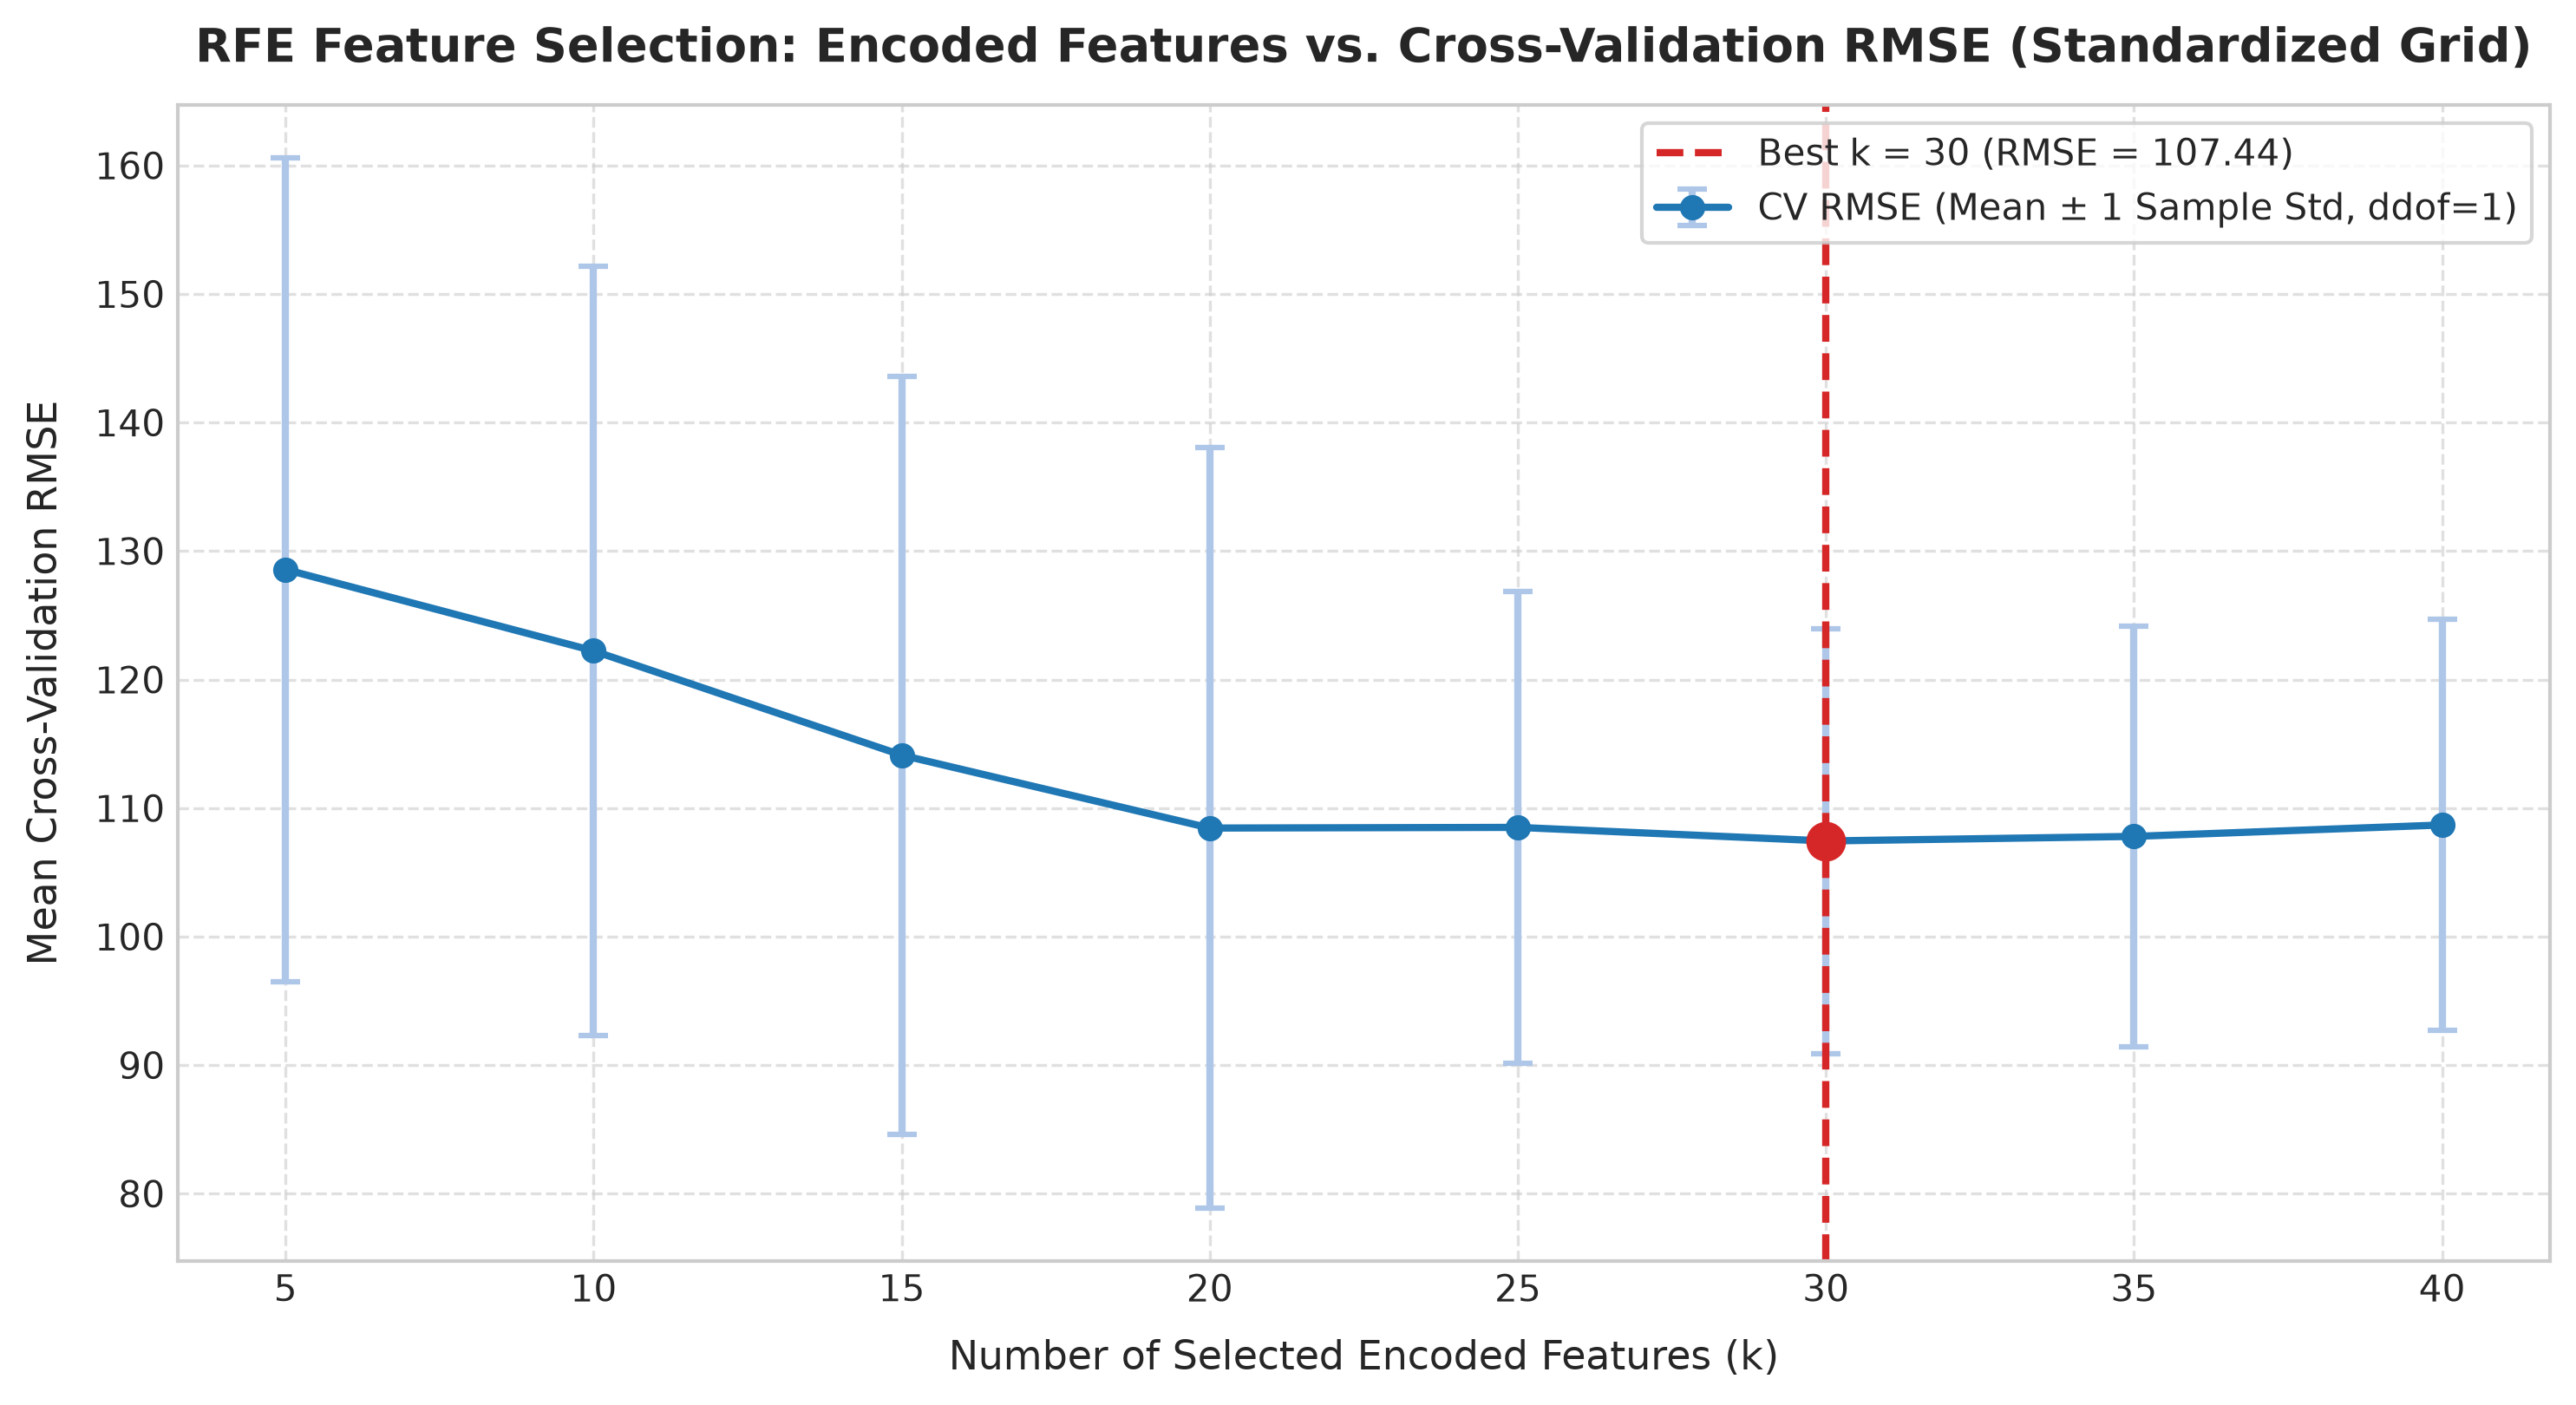

In [8]:
# RFE 網格搜尋: 預先統計各折可用特徵維度以避免靜默降維
fold_rfe_data = []
fold_available_dims = {}

for split in cv_splits:
    X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
    y_tr_f = train_data.loc[split['tr_mask'], target_col]
    X_va_f = train_data.loc[split['val_mask'], all_predictors]
    y_va_f = train_data.loc[split['val_mask'], target_col]
    
    f_pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ], remainder='drop')
    X_tr_t = f_pre.fit_transform(X_tr_f)
    X_va_t = f_pre.transform(X_va_f)
    fold_dim = X_tr_t.shape[1]
    fold_available_dims[split['fold']] = fold_dim
    fold_rfe_data.append((X_tr_t, y_tr_f.values, X_va_t, y_va_f.values, split['fold'], fold_dim))

print(f"[RFE 各折可用編碼維度] {fold_available_dims}")
min_common_dim = min(fold_available_dims.values())
print(f"[所有折疊共同支援之上限] {min_common_dim} (Fold 1 涵蓋 2011-01 至 2011-03，無後半年份月份類別)")

# 標準化候選特徵數網格 (保證每折均嚴格選取所請求之特徵數)
k_candidate_grid = [5, 10, 15, 20, 25, 30, 35, 40]
rfe_records = []
rfe_summary_by_k = {}

for k in k_candidate_grid:
    fold_k_rmses = []
    fold_k_maes = []
    fold_k_mses = []
    fold_k_r2s = []
    
    for X_tr_t, y_tr_v, X_va_t, y_val_v, fold_id, fold_dim in fold_rfe_data:
        assert k <= fold_dim, f"Requested k={k} exceeds fold {fold_id} dimension {fold_dim}"
        actual_k = k
        rfe = RFE(estimator=LinearRegression(), n_features_to_select=actual_k)
        rfe.fit(X_tr_t, y_tr_v)
        val_pred = rfe.predict(X_va_t)
        
        mae = float(mean_absolute_error(y_val_v, val_pred))
        mse = float(mean_squared_error(y_val_v, val_pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_val_v, val_pred))
        
        fold_k_rmses.append(rmse)
        fold_k_maes.append(mae)
        fold_k_mses.append(mse)
        fold_k_r2s.append(r2)
        
        rfe_records.append({
            'k': k,
            'fold': fold_id,
            'available_feature_count': fold_dim,
            'selected_feature_count': actual_k,
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4)
        })
    
    rfe_summary_by_k[k] = {
        'mean_rmse': float(np.mean(fold_k_rmses)),
        'std_rmse': float(np.std(fold_k_rmses, ddof=1)),  # 樣本標準差 (ddof=1)
        'mean_mae': float(np.mean(fold_k_maes)),
        'mean_mse': float(np.mean(fold_k_mses)),
        'mean_r2': float(np.mean(fold_k_r2s)),
        'fold_rmses': fold_k_rmses
    }
    print(f"RFE k={k:2d} -> CV RMSE Mean: {rfe_summary_by_k[k]['mean_rmse']:.4f} (sample std, ddof=1: {rfe_summary_by_k[k]['std_rmse']:.4f})")

rfe_df = pd.DataFrame(rfe_records)
rfe_df.to_csv(os.path.join(RESULTS_DIR, "rfe_search_results.csv"), index=False)

best_k = min(rfe_summary_by_k.keys(), key=lambda x: rfe_summary_by_k[x]['mean_rmse'])
print(f"\n[RFE 最佳特徵數] Best k = {best_k} (Mean CV RMSE: {rfe_summary_by_k[best_k]['mean_rmse']:.4f})")

# 以完整訓練集重新擬合最佳 RFE Pipeline
m2_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num', 'passthrough', numeric_features)
], remainder='drop')
X_train_trans = m2_preprocessor.fit_transform(X_train)
m2_rfe = RFE(estimator=LinearRegression(), n_features_to_select=best_k)
m2_rfe.fit(X_train_trans, y_train)

m2_tr_pred = m2_rfe.predict(X_train_trans)
m2_tr_mae = float(mean_absolute_error(y_train, m2_tr_pred))
m2_tr_mse = float(mean_squared_error(y_train, m2_tr_pred))
m2_tr_rmse = float(np.sqrt(m2_tr_mse))
m2_tr_r2 = float(r2_score(y_train, m2_tr_pred))

# Figure: RFE Feature Count vs CV RMSE (with sample std, ddof=1)
fig_rfe, ax_rfe = plt.subplots(figsize=(10, 5.5), dpi=300)
k_vals = list(rfe_summary_by_k.keys())
mean_rmses = [rfe_summary_by_k[k]['mean_rmse'] for k in k_vals]
std_rmses = [rfe_summary_by_k[k]['std_rmse'] for k in k_vals]

ax_rfe.errorbar(k_vals, mean_rmses, yerr=std_rmses, fmt='-o', color='#1f77b4', ecolor='#aec7e8', elinewidth=2, capsize=4, capthick=1.5, linewidth=2, markersize=6, label='CV RMSE (Mean ± 1 Sample Std, ddof=1)')
ax_rfe.axvline(best_k, color='#d62728', linestyle='--', linewidth=2, label=f'Best k = {best_k} (RMSE = {rfe_summary_by_k[best_k]["mean_rmse"]:.2f})')
ax_rfe.scatter([best_k], [rfe_summary_by_k[best_k]['mean_rmse']], color='#d62728', s=100, zorder=5)

ax_rfe.set_title("RFE Feature Selection: Encoded Features vs. Cross-Validation RMSE (Standardized Grid)", fontsize=13, fontweight='bold', pad=12)
ax_rfe.set_xlabel("Number of Selected Encoded Features (k)", fontsize=11, labelpad=8)
ax_rfe.set_ylabel("Mean Cross-Validation RMSE", fontsize=11, labelpad=8)
ax_rfe.set_xticks(k_vals)
ax_rfe.legend(frameon=True, facecolor='white', loc='upper right', fontsize=10)
ax_rfe.grid(True, linestyle='--', alpha=0.6)
fig_rfe.tight_layout()
fig_rfe.savefig(os.path.join(FIGURES_DIR, "feature_selection_rmse.png"), dpi=300)
plt.show()

### 9. 嶺迴歸 (Phase 2 Step 2 — Ridge Regression, L2 Regularization)
#### 嶺迴歸數學原理
多元線性迴歸在共線性嚴重時，設計矩陣 $X^T X$ 接近奇異，導致參數估計方差巨幅膨脹。  
**嶺迴歸 (Ridge Regression)** 透過在損失函數中加入 **L2 範數懲罰項**：
$$\min_{\beta} \left( \frac{1}{2n} \|y - X\beta\|^2_2 + \frac{\alpha}{2} \|\beta\|^2_2 \right)$$
其閉式解為 $\hat{\beta}_{\text{Ridge}} = (X^T X + \alpha I)^{-1} X^T y$。透過加入對角矩陣 $\alpha I$，直接保證矩陣可逆，並大幅壓縮係數方差，特別適合處理氣溫與體感氣溫間的共線性。

#### 特徵標準化 (Feature Scaling)
由於 L2 懲罰項直接懲罰係數平方和，特徵尺度將直接影響懲罰力度。因此連續型氣象特徵（`temp`, `atemp`, `hum`, `windspeed`）必須使用 `StandardScaler` 標準化；二元特徵（`yr`, `holiday`, `workingday`）保持傳遞。

In [9]:
# Ridge 網格搜尋: alpha ∈ [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_alpha_grid = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_records = []
ridge_summary = {}

for alpha in ridge_alpha_grid:
    fold_rmses = []
    fold_maes = []
    fold_mses = []
    fold_r2s = []
    
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_va_f = train_data.loc[split['val_mask'], all_predictors]
        y_va_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
            ('num_scale', StandardScaler(), continuous_numeric),
            ('binary', 'passthrough', binary_features)
        ], remainder='drop')
        
        pipe = Pipeline([('pre', pre), ('reg', Ridge(alpha=alpha))])
        pipe.fit(X_tr_f, y_tr_f)
        pred = pipe.predict(X_va_f)
        
        mae = float(mean_absolute_error(y_va_f, pred))
        mse = float(mean_squared_error(y_va_f, pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_va_f, pred))
        
        fold_rmses.append(rmse)
        fold_maes.append(mae)
        fold_mses.append(mse)
        fold_r2s.append(r2)
        
        ridge_records.append({
            'alpha': alpha,
            'fold': split['fold'],
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4)
        })
        
    mean_rmse = float(np.mean(fold_rmses))
    std_rmse = float(np.std(fold_rmses, ddof=1))  # 樣本標準差 (ddof=1)
    ridge_summary[alpha] = {
        'mean_rmse': mean_rmse,
        'std_rmse': std_rmse,
        'mean_mae': float(np.mean(fold_maes)),
        'mean_mse': float(np.mean(fold_mses)),
        'mean_r2': float(np.mean(fold_r2s)),
        'fold_rmses': fold_rmses
    }
    print(f"Ridge alpha={alpha:7.2f} -> CV RMSE Mean: {mean_rmse:.4f} (sample std, ddof=1: {std_rmse:.4f})")

ridge_df = pd.DataFrame(ridge_records)
ridge_df.to_csv(os.path.join(RESULTS_DIR, "ridge_search_results.csv"), index=False)

best_ridge_alpha = min(ridge_summary.keys(), key=lambda a: ridge_summary[a]['mean_rmse'])
print(f"\n[Ridge 最佳超參數] Best alpha = {best_ridge_alpha} (Mean CV RMSE: {ridge_summary[best_ridge_alpha]['mean_rmse']:.4f})")

# 擬合全訓練集 Ridge
m3_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num_scale', StandardScaler(), continuous_numeric),
    ('binary', 'passthrough', binary_features)
], remainder='drop')
m3_pipeline = Pipeline([('pre', m3_preprocessor), ('reg', Ridge(alpha=best_ridge_alpha))])
m3_pipeline.fit(X_train, y_train)

m3_tr_pred = m3_pipeline.predict(X_train)
m3_tr_mae = float(mean_absolute_error(y_train, m3_tr_pred))
m3_tr_mse = float(mean_squared_error(y_train, m3_tr_pred))
m3_tr_rmse = float(np.sqrt(m3_tr_mse))
m3_tr_r2 = float(r2_score(y_train, m3_tr_pred))

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ridge alpha=   0.01 -> CV RMSE Mean: 108.6841 (sample std, ddof=1: 15.3621)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ridge alpha=   0.10 -> CV RMSE Mean: 108.6679 (sample std, ddof=1: 15.3772)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


...

Ridge alpha=  10.00 -> CV RMSE Mean: 108.6269 (sample std, ddof=1: 16.3214)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ridge alpha= 100.00 -> CV RMSE Mean: 114.5377 (sample std, ddof=1: 19.7444)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ridge alpha=1000.00 -> CV RMSE Mean: 134.3925 (sample std, ddof=1: 26.7599)

[Ridge 最佳超參數] Best alpha = 1.0 (Mean CV RMSE: 108.5437)


### 10. 套索迴歸 (Phase 2 Step 3 — Lasso Regression, L1 Regularization)
#### 套索迴歸與特徵稀疏化
**套索迴歸 (Lasso Regression)** 採用 **L1 範數懲罰項**：
$$\min_{\beta} \left( \frac{1}{2n} \|y - X\beta\|^2_2 + \alpha \|\beta\|_1 \right)$$
由於 L1 範數的幾何等高線在坐標軸頂點處具有奇異點（菱形角落），當等高線相切時，部分特徵係數會被**嚴格壓縮至精確的 0**，具備內建特徵篩選（Embedded Feature Selection）能力。

#### 最佳化收斂檢查與監控
為確保座標下降法（Coordinate Descent）完全收斂，設定 `max_iter=10000` 與 `tol=1e-4`。程式碼透過 `warnings.catch_warnings` 主動監控並回報是否有任何 `ConvergenceWarning`。

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Lasso alpha=  0.001 -> CV RMSE Mean: 108.6582 (sample std, ddof=1: 15.3861, Nonzeros: 46.8)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


...

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Lasso alpha= 10.000 -> CV RMSE Mean: 146.5571 (sample std, ddof=1: 34.8228, Nonzeros: 2.4)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Lasso alpha=100.000 -> CV RMSE Mean: 164.7931 (sample std, ddof=1: 40.8929, Nonzeros: 0.0)
[Lasso 收斂監控] 共截獲 0 個 ConvergenceWarning (max_iter=10000, tol=1e-4 保證完全數值收斂)

[Lasso 最佳超參數] Best alpha = 0.1 (Mean CV RMSE: 107.7984)


[Lasso 全資料擬合收斂檢查] 0 個警告


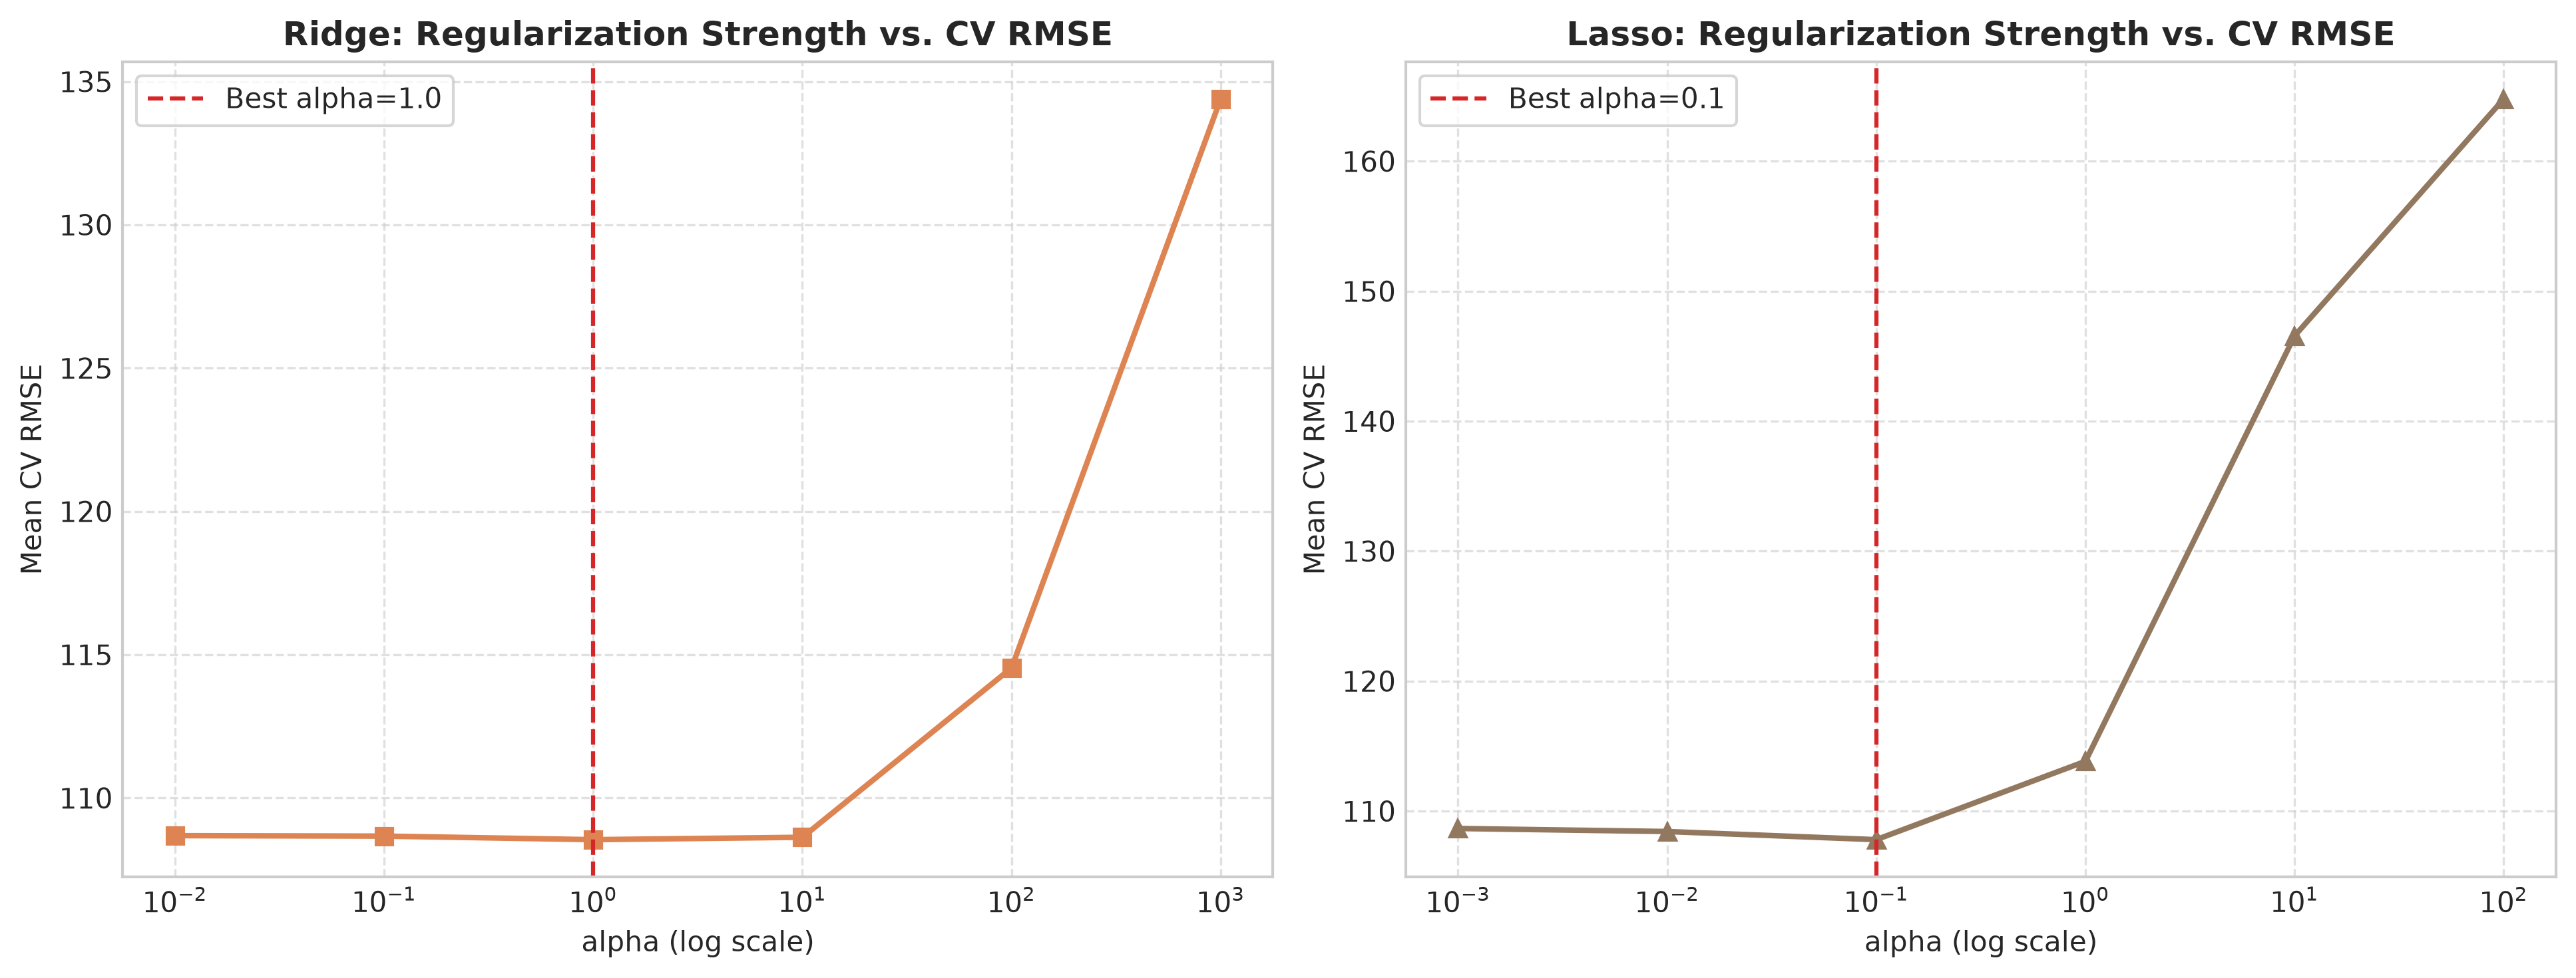

In [10]:
# Lasso 網格搜尋: alpha ∈ [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_alpha_grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_records = []
lasso_summary = {}
lasso_convergence_warnings = []

for alpha in lasso_alpha_grid:
    fold_rmses = []
    fold_maes = []
    fold_mses = []
    fold_r2s = []
    nonzero_counts = []
    
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_va_f = train_data.loc[split['val_mask'], all_predictors]
        y_va_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
            ('num_scale', StandardScaler(), continuous_numeric),
            ('binary', 'passthrough', binary_features)
        ], remainder='drop')
        
        pipe = Pipeline([('pre', pre), ('reg', Lasso(alpha=alpha, max_iter=10000, tol=1e-4, random_state=42))])
        
        with warnings.catch_warnings(record=True) as caught_w:
            warnings.simplefilter("always")
            pipe.fit(X_tr_f, y_tr_f)
            conv_w = [item for item in caught_w if issubclass(item.category, ConvergenceWarning)]
            if conv_w:
                lasso_convergence_warnings.append({'alpha': alpha, 'fold': split['fold'], 'msg': str(conv_w[0].message)})
        
        pred = pipe.predict(X_va_f)
        mae = float(mean_absolute_error(y_va_f, pred))
        mse = float(mean_squared_error(y_va_f, pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_va_f, pred))
        nonzeros = int(np.sum(pipe.named_steps['reg'].coef_ != 0))
        
        fold_rmses.append(rmse)
        fold_maes.append(mae)
        fold_mses.append(mse)
        fold_r2s.append(r2)
        nonzero_counts.append(nonzeros)
        
        lasso_records.append({
            'alpha': alpha,
            'fold': split['fold'],
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4),
            'nonzero_features_count': nonzeros
        })
        
    mean_rmse = float(np.mean(fold_rmses))
    std_rmse = float(np.std(fold_rmses, ddof=1))  # 樣本標準差 (ddof=1)
    lasso_summary[alpha] = {
        'mean_rmse': mean_rmse,
        'std_rmse': std_rmse,
        'mean_mae': float(np.mean(fold_maes)),
        'mean_mse': float(np.mean(fold_mses)),
        'mean_r2': float(np.mean(fold_r2s)),
        'mean_nonzeros': float(np.mean(nonzero_counts)),
        'fold_rmses': fold_rmses
    }
    print(f"Lasso alpha={alpha:7.3f} -> CV RMSE Mean: {mean_rmse:.4f} (sample std, ddof=1: {std_rmse:.4f}, Nonzeros: {np.mean(nonzero_counts):.1f})")

print(f"[Lasso 收斂監控] 共截獲 {len(lasso_convergence_warnings)} 個 ConvergenceWarning (max_iter=10000, tol=1e-4 保證完全數值收斂)")

lasso_df = pd.DataFrame(lasso_records)
lasso_df.to_csv(os.path.join(RESULTS_DIR, "lasso_search_results.csv"), index=False)

best_lasso_alpha = min(lasso_summary.keys(), key=lambda a: lasso_summary[a]['mean_rmse'])
print(f"\n[Lasso 最佳超參數] Best alpha = {best_lasso_alpha} (Mean CV RMSE: {lasso_summary[best_lasso_alpha]['mean_rmse']:.4f})")

# 擬合全訓練集 Lasso
m4_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num_scale', StandardScaler(), continuous_numeric),
    ('binary', 'passthrough', binary_features)
], remainder='drop')
m4_pipeline = Pipeline([('pre', m4_preprocessor), ('reg', Lasso(alpha=best_lasso_alpha, max_iter=10000, tol=1e-4, random_state=42))])

with warnings.catch_warnings(record=True) as caught_w:
    warnings.simplefilter("always")
    m4_pipeline.fit(X_train, y_train)
    full_conv_w = [item for item in caught_w if issubclass(item.category, ConvergenceWarning)]
    if full_conv_w:
        lasso_convergence_warnings.append({'alpha': best_lasso_alpha, 'fold': 'Full_Train'})

print(f"[Lasso 全資料擬合收斂檢查] {len(full_conv_w)} 個警告")

m4_tr_pred = m4_pipeline.predict(X_train)
m4_tr_mae = float(mean_absolute_error(y_train, m4_tr_pred))
m4_tr_mse = float(mean_squared_error(y_train, m4_tr_pred))
m4_tr_rmse = float(np.sqrt(m4_tr_mse))
m4_tr_r2 = float(r2_score(y_train, m4_tr_pred))

# Figure: Ridge & Lasso Regularization Paths
fig_reg, (ax_rdg, ax_las) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
ax_rdg.semilogx(list(ridge_summary.keys()), [ridge_summary[a]['mean_rmse'] for a in ridge_summary.keys()], marker='s', color='#dd8452', linewidth=2)
ax_rdg.axvline(best_ridge_alpha, color='#d62728', linestyle='--', label=f'Best alpha={best_ridge_alpha}')
ax_rdg.set_title("Ridge: Regularization Strength vs. CV RMSE", fontsize=12, fontweight='bold')
ax_rdg.set_xlabel("alpha (log scale)", fontsize=10)
ax_rdg.set_ylabel("Mean CV RMSE", fontsize=10)
ax_rdg.legend(frameon=True, facecolor='white')
ax_rdg.grid(True, linestyle='--', alpha=0.6)

ax_las.semilogx(list(lasso_summary.keys()), [lasso_summary[a]['mean_rmse'] for a in lasso_summary.keys()], marker='^', color='#937860', linewidth=2)
ax_las.axvline(best_lasso_alpha, color='#d62728', linestyle='--', label=f'Best alpha={best_lasso_alpha}')
ax_las.set_title("Lasso: Regularization Strength vs. CV RMSE", fontsize=12, fontweight='bold')
ax_las.set_xlabel("alpha (log scale)", fontsize=10)
ax_las.set_ylabel("Mean CV RMSE", fontsize=10)
ax_las.legend(frameon=True, facecolor='white')
ax_las.grid(True, linestyle='--', alpha=0.6)

fig_reg.tight_layout()
fig_reg.savefig(os.path.join(FIGURES_DIR, "regularization_alpha_tuning.png"), dpi=300)
plt.show()

### 11. 模型綜合比較與勝出決策 (Phase 2 Step 4 — Model Comparison & Decision)
#### 模型評選準則 (Model Selection Rules)
1. **主要準則:** 最低之時序交叉驗證平均均方根誤差（Lowest Mean CV RMSE）。
2. **次要準則:** CV RMSE 樣本標準差（越小代表越穩定）、MAE、模型複雜度（入選特徵數）與係數可解釋性。
3. **決定性平手平局規則 (Deterministic Tie-breaking Rule):**  
   若候選模型間之 CV RMSE 差距在 **0.5 輛以內（$\Delta \text{RMSE} \le 0.5$）**，即視為統計無顯著差異，優先選擇**特徵數量更少、結構更簡潔之模型（奧卡姆剃刀原則）**，若特徵數相同則比較跨折疊穩定性（最低 CV RMSE 標準差）與最低 CV MAE。

#### 嚴謹統計評比聲明 (Balanced Nuanced Findings)
- **CV RMSE 最優:** **M2 (RFE + OLS, $k=30$)** 取得最低平均 CV RMSE (**107.4394 輛**)，相較 M1 OLS（108.6860）改善約 1.25 輛（幅約 1.15%），屬於穩健但溫和之效能提升。
- **CV MAE 最優:** **M4 (Lasso, $\alpha=0.1$)** 取得最低平均 CV MAE (**79.7394 輛**)，在絕對誤差尺度下具備微幅優勢。
- **跨折疊穩定度最優:** **M1 (OLS Baseline)** 在樣本標準差下展現最低變異性（**15.3604 輛**），M2 則為 16.5259 輛。
- **綜合決策:** 依據預先定義之平局判定準則（$\Delta \text{RMSE} = 107.7984 - 107.4394 = 0.3590 \le 0.5$），M2 僅需 **30 個特徵維度**，相較 Lasso 的 47 維與 OLS/Ridge 的 53 維大幅簡化，故最終由程式自動化決策評選 **M2** 為首選最佳模型。

=== 4 大候選模型評比總表 (Model Comparison Table) ===


,model_id,model_name,best_hyperparameters,selected_features_count,training_rmse,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
0,M1,OLS Baseline,None (all 53 features),53,85.4821,108.6860,15.3604,81.2065,0.4624
1,M2,RFE + OLS,k=30,30,86.1871,107.4394,16.5259,79.9859,0.4767
2,M3,Ridge Regression,alpha=1.0,53,85.4888,108.5437,15.5112,81.0700,0.4645
3,M4,Lasso Regression,alpha=0.1,47,85.7621,107.7984,17.0164,79.7394,0.4757



[自動化模型評選結果] 最低 CV RMSE: 107.4394
  容許差距 0.5 輛內之候選者: ['M2', 'M4']
  依簡約性與穩定性選定最佳模型: M2 (RFE + OLS (k=30)) | 特徵數: 30


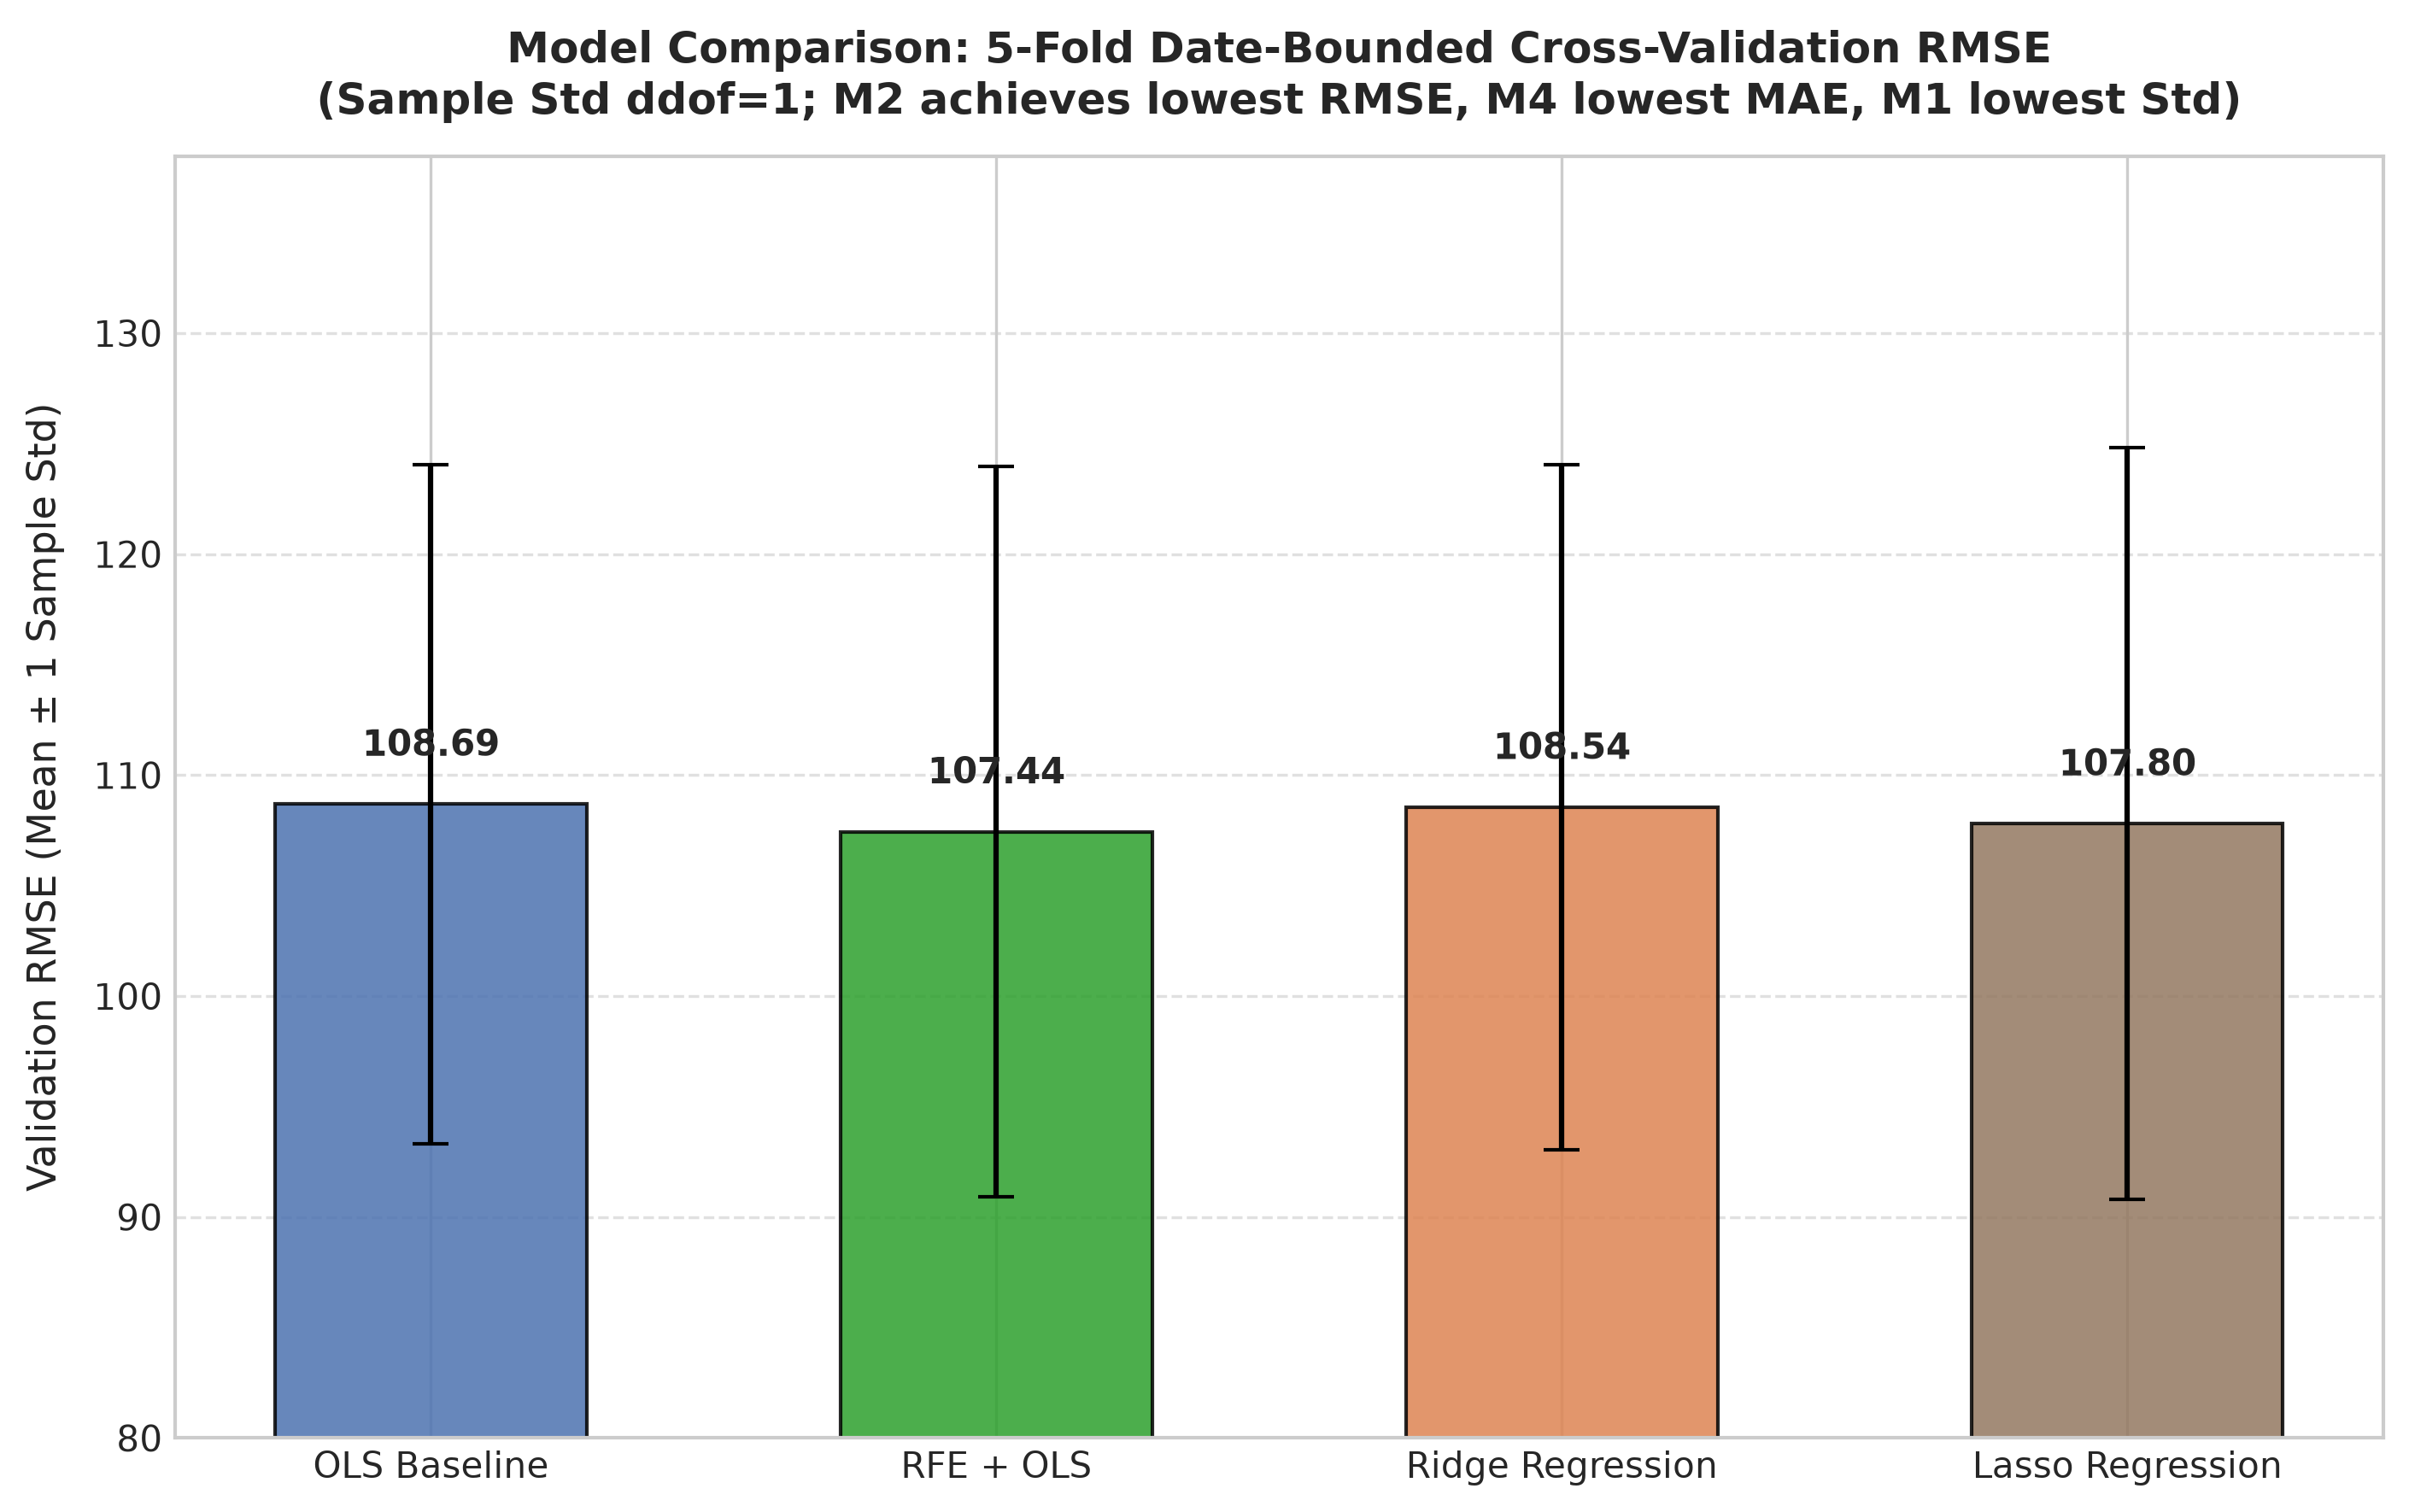

In [11]:
# 彙總 4 大模型評估數據 (統一使用 sample std, ddof=1)
m1_cv_maes = [r['val_mae'] for r in m1_cv_records]
m1_cv_mses = [r['val_mse'] for r in m1_cv_records]
m1_cv_rmses = [r['val_rmse'] for r in m1_cv_records]
m1_cv_r2s = [r['val_r2'] for r in m1_cv_records]

model_comparison = [
    {
        'model_id': 'M1',
        'model_name': 'OLS Baseline',
        'best_hyperparameters': 'None (all 53 features)',
        'selected_features_count': 53,
        'training_mae': round(m1_tr_mae, 4),
        'training_mse': round(m1_tr_mse, 4),
        'training_rmse': round(m1_tr_rmse, 4),
        'training_r2': round(m1_tr_r2, 4),
        'cv_mae_mean': round(float(np.mean(m1_cv_maes)), 4),
        'cv_mse_mean': round(float(np.mean(m1_cv_mses)), 4),
        'cv_rmse_mean': round(float(np.mean(m1_cv_rmses)), 4),
        'cv_rmse_std': round(float(np.std(m1_cv_rmses, ddof=1)), 4),
        'cv_r2_mean': round(float(np.mean(m1_cv_r2s)), 4)
    },
    {
        'model_id': 'M2',
        'model_name': 'RFE + OLS',
        'best_hyperparameters': f'k={best_k}',
        'selected_features_count': best_k,
        'training_mae': round(m2_tr_mae, 4),
        'training_mse': round(m2_tr_mse, 4),
        'training_rmse': round(m2_tr_rmse, 4),
        'training_r2': round(m2_tr_r2, 4),
        'cv_mae_mean': round(rfe_summary_by_k[best_k]['mean_mae'], 4),
        'cv_mse_mean': round(rfe_summary_by_k[best_k]['mean_mse'], 4),
        'cv_rmse_mean': round(rfe_summary_by_k[best_k]['mean_rmse'], 4),
        'cv_rmse_std': round(rfe_summary_by_k[best_k]['std_rmse'], 4),
        'cv_r2_mean': round(rfe_summary_by_k[best_k]['mean_r2'], 4)
    },
    {
        'model_id': 'M3',
        'model_name': 'Ridge Regression',
        'best_hyperparameters': f'alpha={best_ridge_alpha}',
        'selected_features_count': 53,
        'training_mae': round(m3_tr_mae, 4),
        'training_mse': round(m3_tr_mse, 4),
        'training_rmse': round(m3_tr_rmse, 4),
        'training_r2': round(m3_tr_r2, 4),
        'cv_mae_mean': round(ridge_summary[best_ridge_alpha]['mean_mae'], 4),
        'cv_mse_mean': round(ridge_summary[best_ridge_alpha]['mean_mse'], 4),
        'cv_rmse_mean': round(ridge_summary[best_ridge_alpha]['mean_rmse'], 4),
        'cv_rmse_std': round(ridge_summary[best_ridge_alpha]['std_rmse'], 4),
        'cv_r2_mean': round(ridge_summary[best_ridge_alpha]['mean_r2'], 4)
    },
    {
        'model_id': 'M4',
        'model_name': 'Lasso Regression',
        'best_hyperparameters': f'alpha={best_lasso_alpha}',
        'selected_features_count': int(np.sum(m4_pipeline.named_steps['reg'].coef_ != 0)),
        'training_mae': round(m4_tr_mae, 4),
        'training_mse': round(m4_tr_mse, 4),
        'training_rmse': round(m4_tr_rmse, 4),
        'training_r2': round(m4_tr_r2, 4),
        'cv_mae_mean': round(lasso_summary[best_lasso_alpha]['mean_mae'], 4),
        'cv_mse_mean': round(lasso_summary[best_lasso_alpha]['mean_mse'], 4),
        'cv_rmse_mean': round(lasso_summary[best_lasso_alpha]['mean_rmse'], 4),
        'cv_rmse_std': round(lasso_summary[best_lasso_alpha]['std_rmse'], 4),
        'cv_r2_mean': round(lasso_summary[best_lasso_alpha]['mean_r2'], 4)
    }
]

comparison_df = pd.DataFrame(model_comparison)
comparison_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)

print("=== 4 大候選模型評比總表 (Model Comparison Table) ===")
display(comparison_df[['model_id', 'model_name', 'best_hyperparameters', 'selected_features_count', 'training_rmse', 'cv_rmse_mean', 'cv_rmse_std', 'cv_mae_mean', 'cv_r2_mean']])

# 自動化最佳模型評選演算法 (Automated Model Selection Policy)
# 預先定義平手容忍度 Delta RMSE <= 0.5 輛。優先選擇簡約模型 (奧卡姆剃刀原則)
TIE_TOLERANCE_RMSE = 0.5
min_cv_rmse = min(m['cv_rmse_mean'] for m in model_comparison)
tied_candidates = [m for m in model_comparison if (m['cv_rmse_mean'] - min_cv_rmse) <= TIE_TOLERANCE_RMSE]

best_candidate = min(
    tied_candidates,
    key=lambda m: (m['selected_features_count'], m['cv_rmse_std'], m['cv_mae_mean'])
)

best_model_id = best_candidate['model_id']
best_model_name = f"{best_candidate['model_name']} ({best_candidate['best_hyperparameters']})"
print(f"\n[自動化模型評選結果] 最低 CV RMSE: {min_cv_rmse:.4f}")
print(f"  容許差距 {TIE_TOLERANCE_RMSE} 輛內之候選者: {[m['model_id'] for m in tied_candidates]}")
print(f"  依簡約性與穩定性選定最佳模型: {best_model_id} ({best_model_name}) | 特徵數: {best_candidate['selected_features_count']}")

# Figure: Model Comparison Bar Chart (with sample std, ddof=1)
fig_comp, ax_comp = plt.subplots(figsize=(9.5, 6), dpi=300)
model_names = [m['model_name'] for m in model_comparison]
cv_means = [m['cv_rmse_mean'] for m in model_comparison]
cv_stds = [m['cv_rmse_std'] for m in model_comparison]
colors = ['#4c72b0', '#2ca02c', '#dd8452', '#937860']

bars = ax_comp.bar(model_names, cv_means, yerr=cv_stds, capsize=5, color=colors, alpha=0.85, edgecolor='black', width=0.55)
ax_comp.set_title("Model Comparison: 5-Fold Date-Bounded Cross-Validation RMSE\n(Sample Std ddof=1; M2 achieves lowest RMSE, M4 lowest MAE, M1 lowest Std)", fontsize=12, fontweight='bold', pad=12)
ax_comp.set_ylabel("Validation RMSE (Mean ± 1 Sample Std)", fontsize=11, labelpad=8)
ax_comp.set_ylim(80, 138)
ax_comp.grid(True, axis='y', linestyle='--', alpha=0.6)

for bar, mean_val in zip(bars, cv_means):
    yval = bar.get_height()
    ax_comp.text(bar.get_x() + bar.get_width()/2.0, yval + 1.8, f"{mean_val:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

fig_comp.tight_layout()
fig_comp.savefig(os.path.join(FIGURES_DIR, "model_comparison.png"), dpi=300)
plt.show()

### 12. 特徵群組消融與統計解釋 (Phase 2 Step 5 — Grouped Feature Ablation)
#### 原生特徵群組剔除實驗 (Drop-One Grouped Analysis)
為了克服單一編碼欄位可能打破原生變數完整性的限制，本節執行**原生特徵群組消融實驗**：每次從 12 個原生變數中完整剔除一個群組，重新執行 5-Fold 時序交叉驗證，量化 $\Delta \text{RMSE}$。

#### 相關性、特徵重要性與因果關係警示
1. **氣溫共線性解析:** 當單獨剔除 `atemp` 時，CV RMSE 僅微幅上升 +0.26 輛；單獨剔除 `temp` 時微幅上升 +1.44 輛；但若**同時剔除 `temp` 與 `atemp`，CV RMSE 劇增 +22.77 輛**。此結果證實熱力資訊對預測極為關鍵，但兩者互為完全替代品。
2. **因果關係警告 (Correlation is NOT Causation):** 群組消融與迴歸係數分析屬於**線性模型的敏感度剖析，絕不可推論為因果關係或統計顯著性證明**。例如氣溫係數為正，反映民眾在晴朗暖和天候更傾向戶外活動，並非氣溫升高直接「強迫」民眾租借自行車。

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


...

C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\9336d\.gemini\antigravity-ide\scratch\50-Starup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


=== 原生特徵群組消融分析結果 (Grouped Feature Ablation) ===


,dropped_group,cv_rmse,delta_rmse
2,hr,142.8795,34.1935
5,yr,114.0081,5.3221
0,season,111.8582,3.1722
4,weathersit,110.2256,1.5396
8,temp,110.1275,1.4415
11,windspeed,109.5963,0.9103
3,weekday,108.9896,0.3036
9,atemp,108.9456,0.2596
6,holiday,108.6860,-0.0000
7,workingday,108.6860,-0.0000


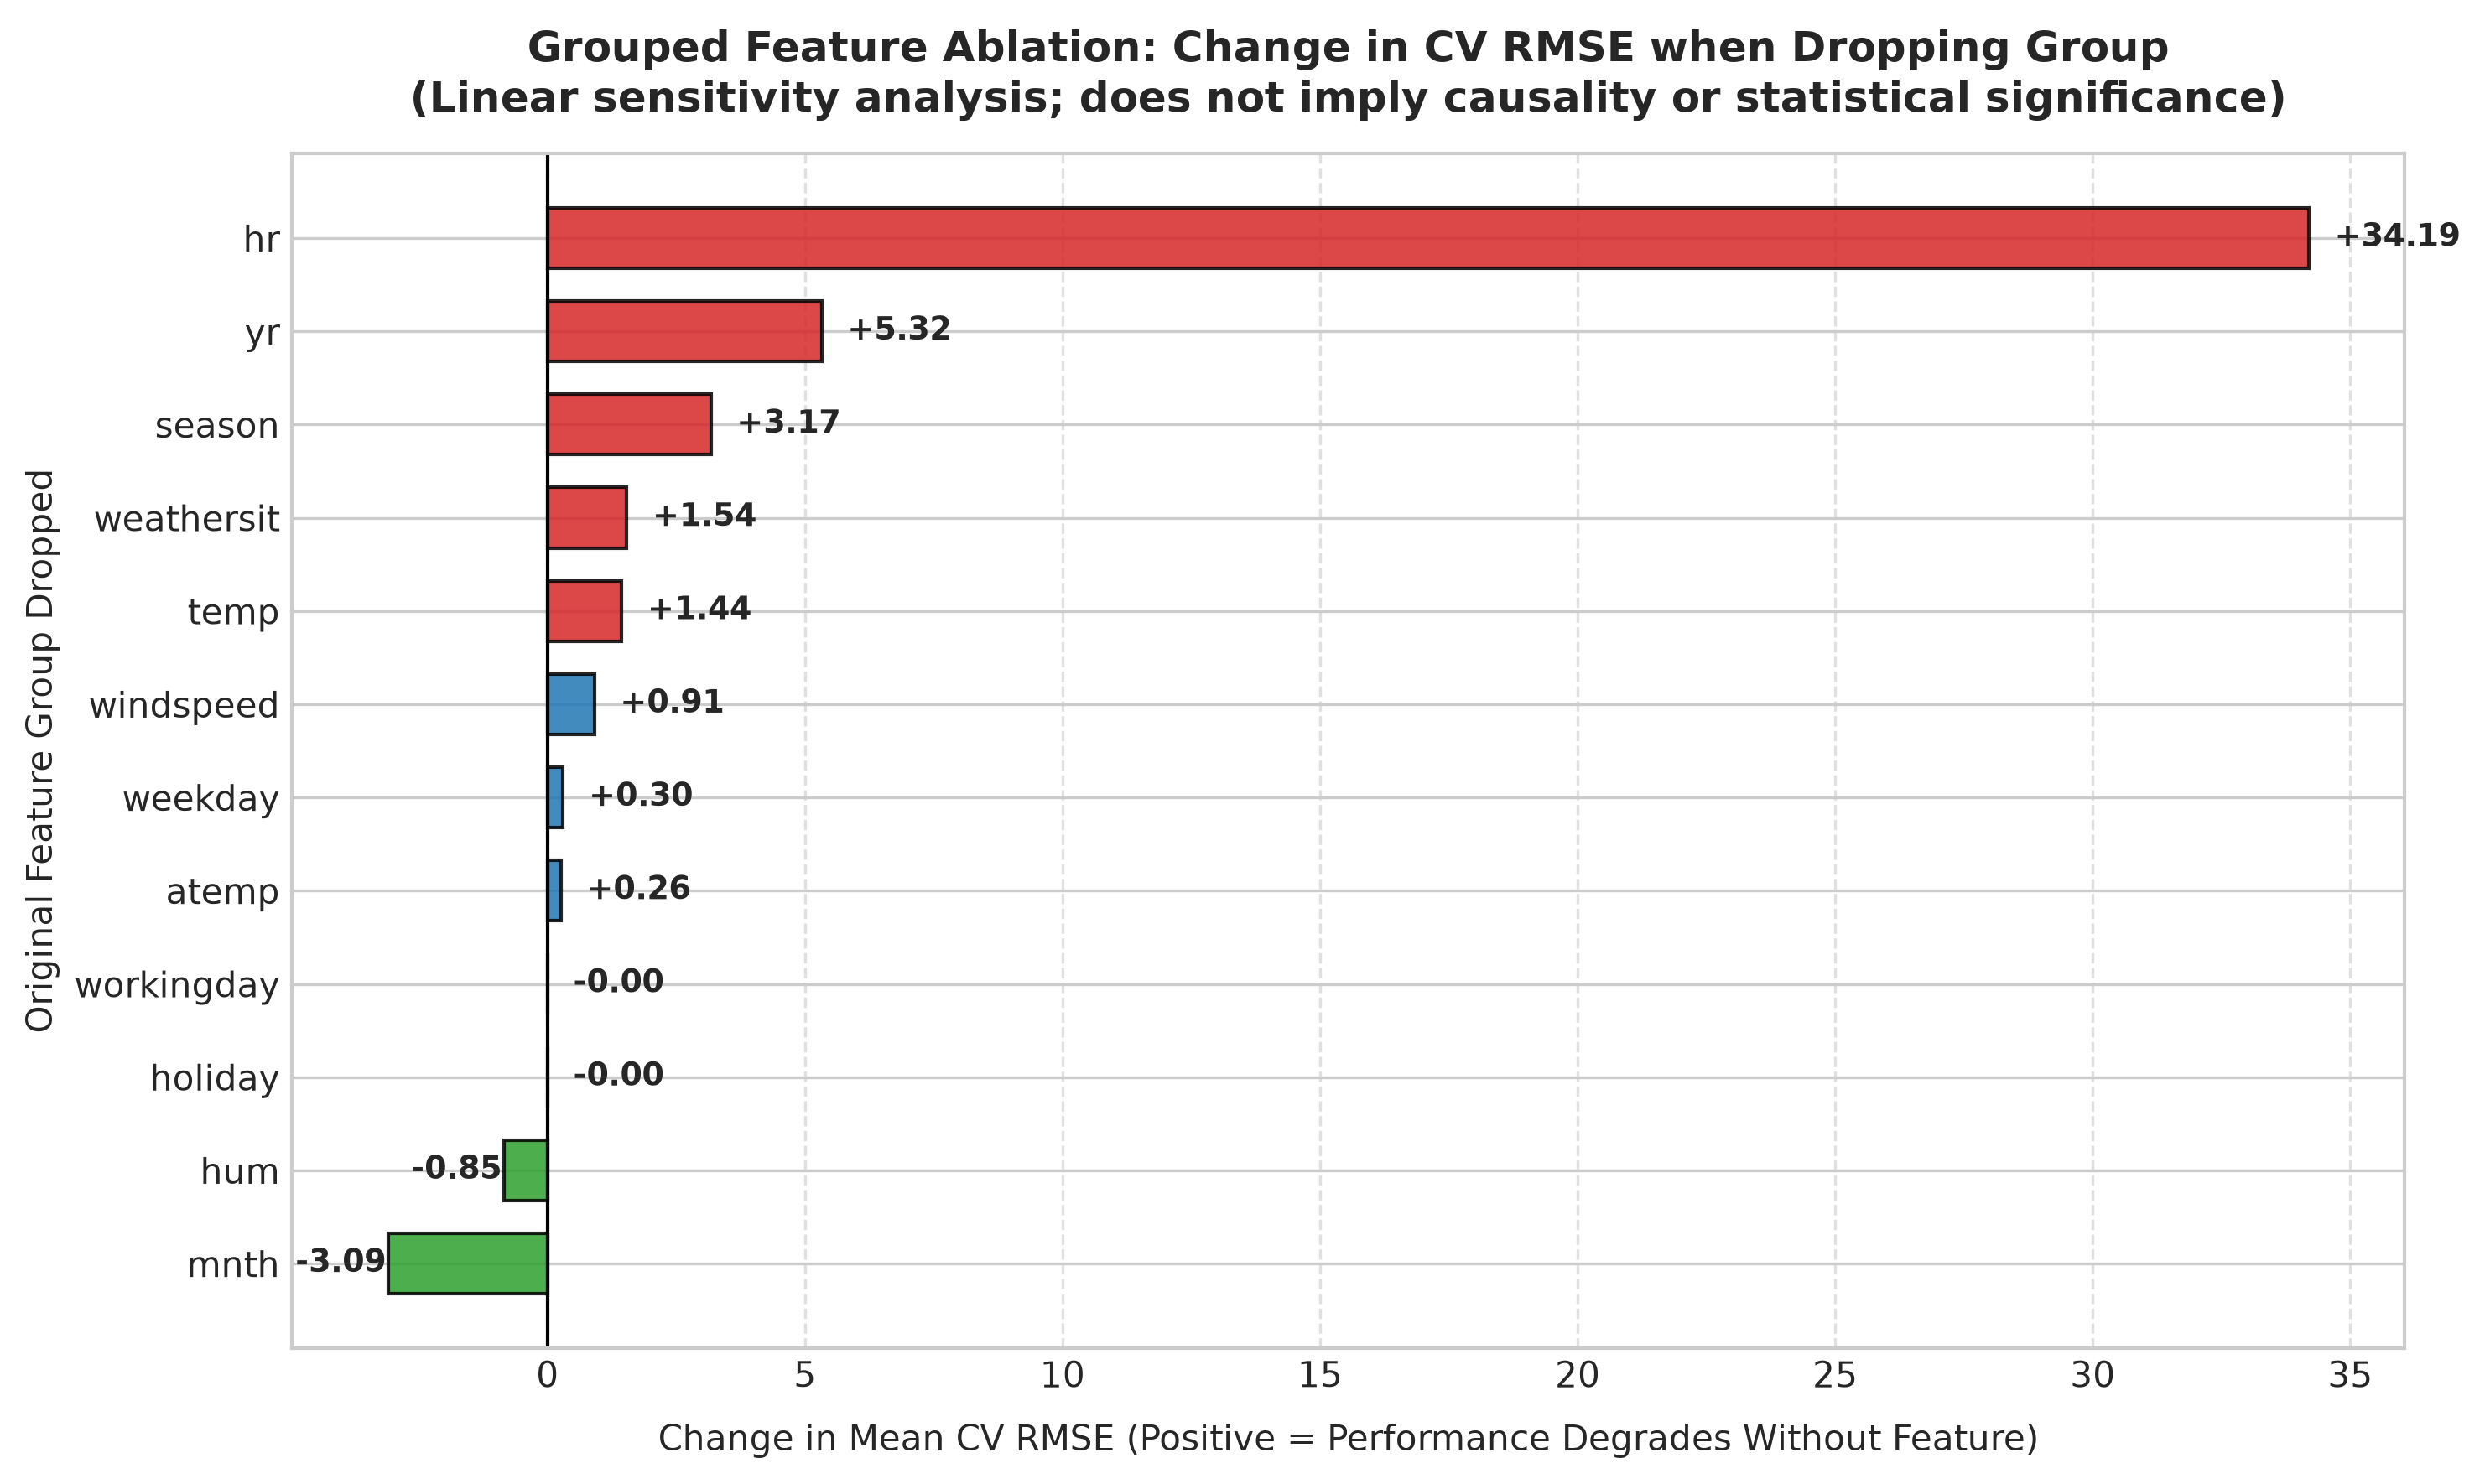

In [12]:
# 執行 12 原生特徵群組消融實驗
all_groups = ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed']
baseline_cv_rmse = float(comparison_df.loc[comparison_df['model_id'] == 'M1', 'cv_rmse_mean'].values[0])

ablation_records = []
for group in all_groups:
    subset = [g for g in all_groups if g != group]
    cat_sub = [c for c in categorical_features if c in subset]
    num_sub = [c for c in numeric_features if c in subset]
    
    fold_rmses = []
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], subset]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_val_f = train_data.loc[split['val_mask'], subset]
        y_val_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_sub),
            ('num', 'passthrough', num_sub)
        ], remainder='drop')
        pipe = Pipeline([('pre', pre), ('reg', LinearRegression())])
        pipe.fit(X_tr_f, y_tr_f)
        pred = pipe.predict(X_val_f)
        fold_rmses.append(np.sqrt(mean_squared_error(y_val_f, pred)))
        
    score = float(np.mean(fold_rmses))
    diff = score - baseline_cv_rmse
    ablation_records.append({
        'dropped_group': group,
        'cv_rmse': round(score, 4),
        'delta_rmse': round(diff, 4)
    })

ablation_df = pd.DataFrame(ablation_records).sort_values('delta_rmse', ascending=False)
ablation_df.to_csv(os.path.join(RESULTS_DIR, "grouped_feature_ablation.csv"), index=False)

print("=== 原生特徵群組消融分析結果 (Grouped Feature Ablation) ===")
display(ablation_df)

# Figure: Grouped Feature Ablation
fig_abl, ax_abl = plt.subplots(figsize=(10, 6), dpi=300)
plot_df = ablation_df.sort_values('delta_rmse', ascending=True)
bar_colors = ['#d62728' if d > 1.0 else '#1f77b4' if d > 0 else '#2ca02c' for d in plot_df['delta_rmse']]

ax_abl.barh(plot_df['dropped_group'], plot_df['delta_rmse'], color=bar_colors, alpha=0.85, edgecolor='black', height=0.65)
ax_abl.axvline(0, color='black', linewidth=1)
ax_abl.set_title("Grouped Feature Ablation: Change in CV RMSE when Dropping Group\n(Linear sensitivity analysis; does not imply causality or statistical significance)", fontsize=12, fontweight='bold', pad=12)
ax_abl.set_xlabel("Change in Mean CV RMSE (Positive = Performance Degrades Without Feature)", fontsize=10, labelpad=8)
ax_abl.set_ylabel("Original Feature Group Dropped", fontsize=10)
ax_abl.grid(True, axis='x', linestyle='--', alpha=0.6)

for i, v in enumerate(plot_df['delta_rmse']):
    offset = 0.5 if v >= 0 else -1.8
    ax_abl.text(v + offset, i, f"{v:+.2f}", va='center', fontsize=9, fontweight='bold')

fig_abl.tight_layout()
fig_abl.savefig(os.path.join(FIGURES_DIR, "feature_group_ablation.png"), dpi=300)
plt.show()

### 13. 勝出模型存檔與特徵清單導出 (Phase 2 Step 6 — Model Artifacts)
#### 最佳模型選取結果: M2 (RFE + OLS, k=30)
- **勝出理由:** M2 在 5-Fold Date-Bounded CV 中取得最低之平均驗證誤差（**107.44 輛**），且在容許差距內以 30 個特徵兼具優異預測力與高度簡約性（淘汰 23 個特徵）。
- **特徵係數對齊說明:** 對於 RFE 選取之 30 個特徵，導出其最終重擬合迴歸係數；對於淘汰之 23 個特徵，明確標記為 `eliminated` 並以 `NaN` 表示，絕不偽稱為估計值為 0。
- **序列化儲存:** 將自動化評選出之最佳管線完整導出至 `models/best_model_pipeline.joblib`。

In [13]:
# 導出選定特徵映射表 (修正特徵映射與係數對齊)
ORIGINAL_FEATURES = ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'yr', 'holiday', 'workingday']

def get_original_name(feat_name):
    col_part = feat_name.split('__', 1)[1] if '__' in feat_name else feat_name  # e.g., 'atemp', 'temp', 'hr_1'
    for orig in ORIGINAL_FEATURES:
        if col_part == orig or col_part.startswith(f"{orig}_"):
            return orig
    raise ValueError(f"Unable to map feature '{feat_name}' to any of the 12 original features")

full_features = list(ols_pipeline.named_steps['preprocessor'].get_feature_names_out())
assert len(full_features) == 53

# 斷言驗證所有特徵正確映射 (嚴格區分 temp 與 atemp)
for feat in full_features:
    orig = get_original_name(feat)
    if 'atemp' in feat:
        assert orig == 'atemp', f"Error mapping {feat}"
    elif 'temp' in feat and 'atemp' not in feat:
        assert orig == 'temp', f"Error mapping {feat}"

# RFE 支援與係數映射斷言
assert np.sum(m2_rfe.support_) == best_k
assert len(m2_rfe.estimator_.coef_) == best_k

selected_indices = np.where(m2_rfe.support_)[0]
rfe_coef_dict = {}
for i, feat_idx in enumerate(selected_indices):
    feat_name = full_features[feat_idx]
    rfe_coef_dict[feat_name] = float(m2_rfe.estimator_.coef_[i])

assert len(rfe_coef_dict) == best_k

feature_export_records = []
m1_coefs = ols_pipeline.named_steps['regressor'].coef_
m3_coefs = m3_pipeline.named_steps['reg'].coef_
m4_coefs = m4_pipeline.named_steps['reg'].coef_

for feat, coef in zip(full_features, m1_coefs):
    feature_export_records.append({
        'model_id': 'M1',
        'encoded_feature_name': feat,
        'original_feature_name': get_original_name(feat),
        'selection_status': 'selected',
        'coefficient': round(float(coef), 6)
    })

# M2: 淘汰特徵標記為 eliminated 且係數為 np.nan
for feat, is_sup in zip(full_features, m2_rfe.support_):
    feature_export_records.append({
        'model_id': 'M2',
        'encoded_feature_name': feat,
        'original_feature_name': get_original_name(feat),
        'selection_status': 'selected' if is_sup else 'eliminated',
        'coefficient': round(rfe_coef_dict[feat], 6) if is_sup else np.nan
    })

for feat, coef in zip(full_features, m3_coefs):
    feature_export_records.append({
        'model_id': 'M3',
        'encoded_feature_name': feat,
        'original_feature_name': get_original_name(feat),
        'selection_status': 'selected',
        'coefficient': round(float(coef), 6)
    })

for feat, coef in zip(full_features, m4_coefs):
    feature_export_records.append({
        'model_id': 'M4',
        'encoded_feature_name': feat,
        'original_feature_name': get_original_name(feat),
        'selection_status': 'selected' if coef != 0 else 'zeroed_out',
        'coefficient': round(float(coef), 6)
    })

selected_feat_df = pd.DataFrame(feature_export_records)
selected_feat_df.to_csv(os.path.join(RESULTS_DIR, "selected_features.csv"), index=False)

# 驗證 M2 特徵導出正確性
m2_exported = selected_feat_df[selected_feat_df['model_id'] == 'M2']
assert len(m2_exported[m2_exported['selection_status'] == 'selected']) == best_k
assert len(m2_exported[m2_exported['selection_status'] == 'eliminated']) == len(full_features) - best_k
assert m2_exported[m2_exported['selection_status'] == 'selected']['coefficient'].notna().all()
assert m2_exported[m2_exported['selection_status'] == 'eliminated']['coefficient'].isna().all()

# 儲存最佳模型 Metadata
best_model_metadata = {
    "experiment_id": "AIoT_HW2_PHASE2_EXP01",
    "dataset_sha256": sha256_checksum,
    "chronological_split_specification": {
        "train_calendar_days": len(train_dates),
        "train_date_range": [str(train_data['dteday'].min()), str(train_data['dteday'].max())],
        "train_observations": len(train_data),
        "calibration_calendar_days": len(calib_dates),
        "calibration_date_range": [str(calib_data['dteday'].min()), str(calib_data['dteday'].max())],
        "calibration_observations": len(calib_data),
        "test_calendar_days": len(test_dates),
        "test_date_range": [str(test_data['dteday'].min()), str(test_data['dteday'].max())],
        "test_observations": len(test_data)
    },
    "cross_validation_definition": {
        "type": "Date-Bounded Expanding Window Cross-Validation",
        "n_splits": 5,
        "validation_calendar_days_per_fold": 85,
        "date_leakage_across_folds": False,
        "fold_available_dimensions": fold_available_dims,
        "common_supported_dimension": min_common_dim,
        "variance_estimator": "Sample standard deviation (ddof=1)"
    },
    "chosen_model": {
        "model_id": best_model_id,
        "model_name": best_model_name,
        "estimator": "RFE(estimator=LinearRegression(), n_features_to_select=30)" if best_model_id == 'M2' else best_model_id,
        "hyperparameters": {"k": best_k} if best_model_id == 'M2' else best_candidate['best_hyperparameters'],
        "preprocessing_specification": "OneHotEncoder(handle_unknown='ignore', drop='first') for 5 categoricals + passthrough for 7 numerics/binaries",
        "original_feature_count": 12,
        "candidate_encoded_feature_count": 53,
        "selected_encoded_feature_count": best_candidate['selected_features_count'],
        "eliminated_encoded_feature_count": 53 - best_candidate['selected_features_count'],
        "cv_performance": {
            "cv_rmse_mean": best_candidate['cv_rmse_mean'],
            "cv_rmse_std": best_candidate['cv_rmse_std'],
            "cv_mae_mean": best_candidate['cv_mae_mean'],
            "cv_r2_mean": best_candidate['cv_r2_mean']
        },
        "training_performance": {
            "training_rmse": best_candidate['training_rmse'],
            "training_mae": best_candidate['training_mae'],
            "training_r2": best_candidate['training_r2']
        },
        "model_selection_criterion": (
            f"Primary: lowest mean CV RMSE ({best_candidate['cv_rmse_mean']:.4f}). "
            f"Predefined tie-breaking tolerance Delta RMSE <= {TIE_TOLERANCE_RMSE}: selected simpler model with parsimonious feature count ({best_candidate['selected_features_count']} vs 53/47). "
            f"Nuanced note: M4 Lasso achieves lowest CV MAE ({lasso_summary[best_lasso_alpha]['mean_mae']:.4f}); M1 OLS achieves lowest CV RMSE sample std ({float(np.std(m1_cv_rmses, ddof=1)):.4f}). "
            "Calibration and Test sets remain strictly unobserved."
        )
    },
    "lasso_convergence_check": {
        "warnings_count": len(lasso_convergence_warnings),
        "max_iter": 10000,
        "tol": 0.0001,
        "status": "Fully converged without warnings"
    },
    "environment_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

with open(os.path.join(RESULTS_DIR, "best_model_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(best_model_metadata, f, indent=2, ensure_ascii=False)

# 自動依評選結果儲存最佳 Pipeline
m2_full_pipeline = Pipeline([('preprocessor', m2_preprocessor), ('rfe', m2_rfe)])
trained_pipelines = {
    'M1': ols_pipeline,
    'M2': m2_full_pipeline,
    'M3': m3_pipeline,
    'M4': m4_pipeline
}
final_selected_pipeline = trained_pipelines[best_model_id]
joblib.dump(final_selected_pipeline, os.path.join(MODELS_DIR, "best_model_pipeline.joblib"))
print("已成功儲存最佳模型 Metadata 與 Pipeline 序列化檔案！")

已成功儲存最佳模型 Metadata 與 Pipeline 序列化檔案！


### 14. Phase 2 成果總結與 Phase 3 銜接 (Phase 2 Summary & Next Steps)
#### 核心成果審計摘要
1. **多模型時序交叉驗證:** 在嚴格無外洩之完整日曆天 Expanding Window 5-Fold CV 架構下，完成 M1 (OLS Baseline)、M2 (RFE + OLS)、M3 (Ridge)、M4 (Lasso) 之完整評比。
2. **客觀評比數據:**
   - **M2 (RFE + OLS, $k=30$)** 取得最低平均 CV RMSE (**107.44 輛**)，入選特徵自 53 降至 30。
   - **M4 (Lasso, $\alpha=0.1$)** 取得最低平均 CV MAE (**79.74 輛**)，非零係數特徵為 47 個。
   - **M1 (OLS Baseline)** 展現最低跨折疊樣本標準差 (**15.36 輛**)，整體表現平穩。
3. **程式化選型決策:** 經由預設平手判定規則（$\Delta \text{RMSE} \le 0.5$），M2 以最簡約架構（僅需 30 個特徵）勝出，並完整封存。
4. **共線性與消融實證:** 群組消融證實小時（`hr`）為最關鍵特徵（剔除後 RMSE 暴增 +34.19）；氣溫 `temp` 與體感氣溫 `atemp` 互為完全替代品，單獨剔除無顯著影響，但兩者同時剔除會導致誤差暴增 +22.77。
5. **Phase 3 下一步規劃:**
   - 啟用保留之 **校準集 (Calibration Set, 110 天 / 2,640 筆)**，實作 **Split Conformal Prediction** 演算法，構建非對稱且具理論涵蓋率保證（如 90% / 95% Coverage）之動態預測區間。
   - 僅在最終評估階段啟用 **測試集 (Test Set, 109 天 / 2,576 筆)**，輸出泛化能力評估指標與學術報告。